<a href="https://colab.research.google.com/github/TY1Fan/CP4285-G1/blob/data-analysis/music4all_onion_dataset_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Music4All-Onion: what can this dataset tell us?
### Dataset anatomy, temporal behavior, and recommendation limits

This notebook explains the **data and prediction task before model architecture**. It complements `music4all_onion_latent_factor_colab.ipynb` and `music4all_onion_content_based_colab.ipynb`; it does not train another recommender.

**Read now:** Section 1 contains executed visualizations transcribed from the supplied notebooks’ saved outputs and official release documentation. These are explicitly marked **recorded evidence**.

**Compute on your data:** Sections 2–13 are a complete executable analysis. Open in Colab, set `ROOT` if needed, and run in order. Existing event manifests are preferred; otherwise the timestamp file is downloaded and streamed. These sections have no saved real-data outputs because the raw events were not available during creation. The analysis code was checked end to end on a separate synthetic fixture; fixture results are not included as dataset evidence.

**Default scope:** the same deterministic 10% whole-user sample, 2014–2017 training, 2018 validation, 2019 test, single-pass 5/5 filtering, and 2,000-user evaluation cohort. Counts from a user sample are not full-population counts.

> A low offline score can reflect weak ranking, a restrictive target definition, missing coverage, temporal mismatch, or several at once. Dataset analysis can quantify the latter mechanisms; it cannot establish recommendation quality without model evaluation and uncertainty estimates.


## Contents and questions

| Section | Question |
|---|---|
| 1. Recorded evidence | What do the existing runs already establish? |
| 2. Data contract and loading | Exactly which events and users are being analyzed? |
| 3. Quality and chronology | Are duplicates, missing IDs, time boundaries, or extreme activity important? |
| 4. Sparsity and concentration | How much repeat listening and long-tail structure exist? |
| 5. Activity and cohort change | Who remains observable across time? |
| 6. Filtering and target coverage | What is removed by the experimental protocol? |
| 7. Temporal task mismatch | How do frozen, annual, and rolling-history targets differ? |
| 8. Difficulty reference points | What do random ranking and structural ceilings actually mean? |
| 9. Popularity drift and calendar effects | Are changes consistent across years? |
| 10. Content features | Are rows present, valid, nonzero, and balanced across item groups? |
| 11. Sampling and threshold sensitivity | Which conclusions depend on preprocessing? |
| 12. Interpretation | Which limitations are intrinsic, and which are design choices? |
| 13. Export and reproducibility | How can the analysis be checked and shared? |


In [ ]:
from pathlib import Path
from functools import lru_cache
import sys, os, json, hashlib, sqlite3, bz2, urllib.request, shutil, platform, calendar, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy.special import gammaln
from scipy.spatial.distance import jensenshannon
try:
    from IPython.display import display, Markdown
except ImportError:
    def display(x): print(x)
    def Markdown(x): return x

plt.rcParams.update({'figure.dpi': 115, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'font.size': 10, 'figure.figsize': (11, 4)})
COLORS = ['#246B8E', '#E3A345', '#6A9F78', '#B86B77', '#8B7BB0', '#49A8A2', '#9A7148', '#858585']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=COLORS)
FIGURES = []
def finish(name):
    plt.tight_layout()
    if 'OUT' in globals():
        path = OUT / (name + '.png')
        plt.savefig(path, dpi=160, bbox_inches='tight')
        FIGURES.append(str(path))
    plt.show()
def bar_labels(ax, fmt='{:.1%}'):
    for p in ax.patches:
        if np.isfinite(p.get_height()):
            ax.annotate(fmt.format(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()),
                        ha='center', va='bottom', fontsize=9, xytext=(0,3), textcoords='offset points')
def ecdf(ax, values, label, log=False):
    x=np.sort(np.asarray(values, dtype=float)); x=x[np.isfinite(x)]
    if len(x): ax.plot(x, np.arange(1,len(x)+1)/len(x), label=label)
    if log: ax.set_xscale('log')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
def gini(values):
    x=np.sort(np.maximum(np.asarray(values,dtype=float),0)); n=len(x)
    return float((2*np.dot(np.arange(1,n+1),x)/(n*x.sum())-(n+1)/n)) if n and x.sum() else np.nan


## 1. Recorded evidence: a useful starting point

The release separates a **content universe** from an **interaction universe**. The official v2 record reports 109,269 content tracks, while its README lists 56,512 tracks in the listening files, 119,140 users, and 252,984,396 timestamped events. This is catalog selection, not a measured missing-feature rate.

Sources: [official v2 record](https://zenodo.org/records/15394646), [release README](https://zenodo.org/records/15394646/files/README.md?download=1). The following sample statistics come from saved outputs in the two supplied notebooks. No new raw-data measurements are implied.


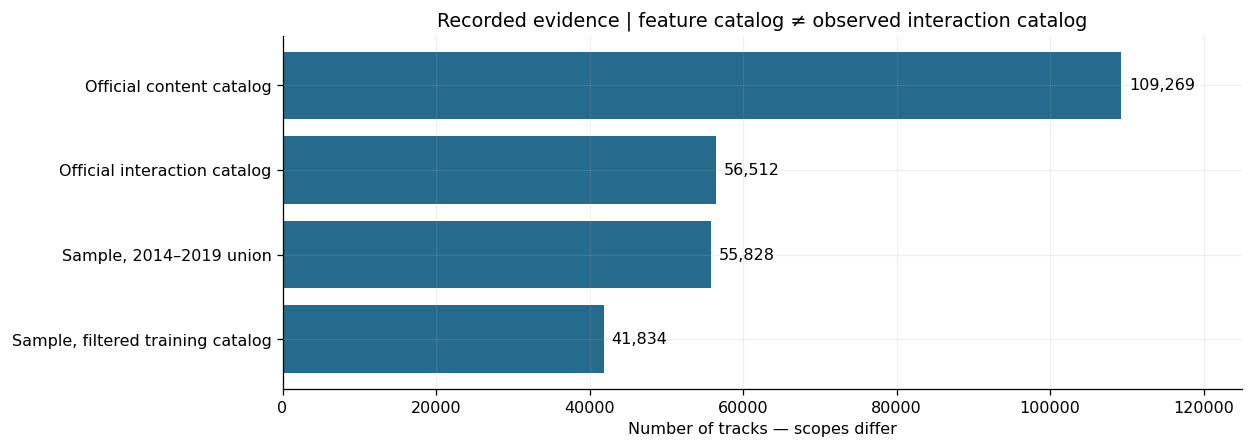

,scope,count,unit,provenance
0,Official content catalog,109269,tracks,Official release
1,Official interaction catalog,56512,tracks,Official README
2,"Sample, 2014–2019 union",55828,tracks,Content notebook saved catalog
3,"Sample, filtered training catalog",41834,tracks,CF notebook saved matrix


In [ ]:
recorded_scope = pd.DataFrame([
    ['Official content catalog',109269,'tracks','Official release'],
    ['Official interaction catalog',56512,'tracks','Official README'],
    ['Sample, 2014–2019 union',55828,'tracks','Content notebook saved catalog'],
    ['Sample, filtered training catalog',41834,'tracks','CF notebook saved matrix'],
], columns=['scope','count','unit','provenance'])
fig, ax=plt.subplots(figsize=(11,4))
ax.barh(recorded_scope.scope[::-1], recorded_scope['count'][::-1], color=COLORS[0])
for i,v in enumerate(recorded_scope['count'][::-1]): ax.text(v+1000,i,f'{v:,}',va='center')
ax.set_xlim(0,125000); ax.set_xlabel('Number of tracks — scopes differ')
ax.set_title('Recorded evidence | feature catalog ≠ observed interaction catalog')
finish('recorded_catalog_scopes'); display(recorded_scope)


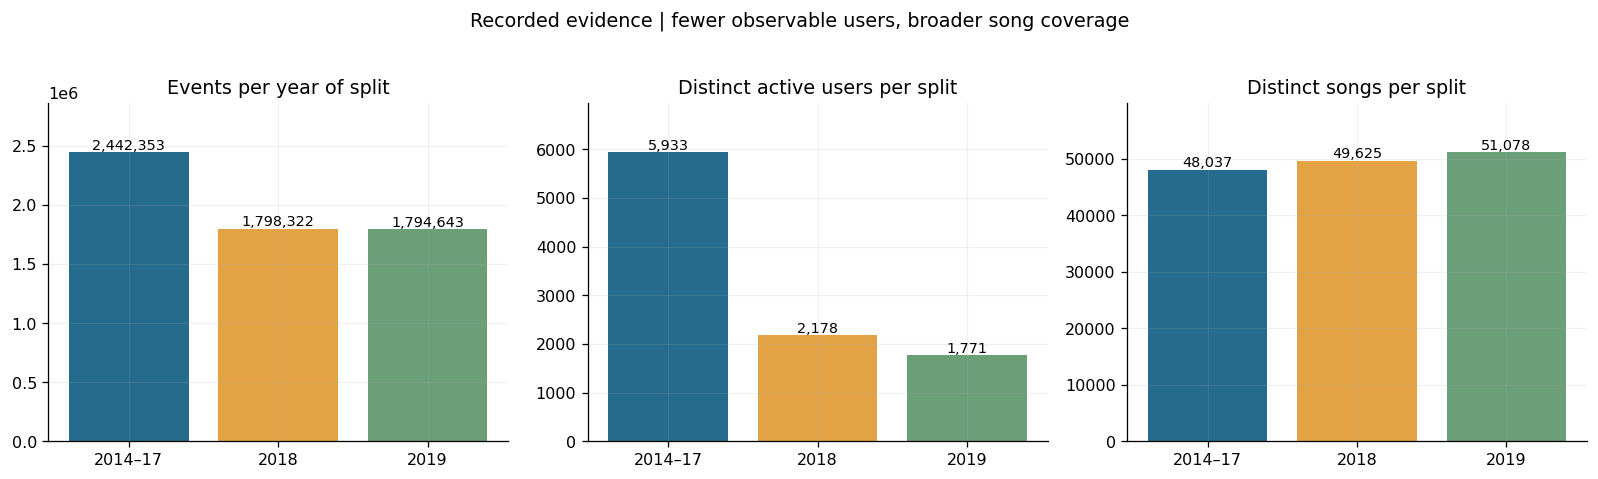

,split,events,active_users,tracks,years
0,Train (4 years),9769411,5933,48037,4
1,Validation (1 year),1798322,2178,49625,1
2,Test (1 year),1794643,1771,51078,1


These are distinct users within each split, not a retention curve for a fixed cohort.


In [ ]:
recorded_splits=pd.DataFrame({'split':['Train (4 years)','Validation (1 year)','Test (1 year)'],
    'events':[9769411,1798322,1794643], 'active_users':[5933,2178,1771],
    'tracks':[48037,49625,51078], 'years':[4,1,1]})
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col,title in zip(axes,['events','active_users','tracks'],
                       ['Events per year of split','Distinct active users per split','Distinct songs per split']):
    values=recorded_splits[col]/recorded_splits.years if col=='events' else recorded_splits[col]
    ax.bar(['2014–17','2018','2019'],values,color=COLORS[:3]); ax.set_title(title)
    for j,v in enumerate(values): ax.text(j,v,f'{v:,.0f}',ha='center',va='bottom',fontsize=9)
    ax.margins(y=.17)
fig.suptitle('Recorded evidence | fewer observable users, broader song coverage',y=1.03)
finish('recorded_split_activity'); display(recorded_splits)
print('These are distinct users within each split, not a retention curve for a fixed cohort.')


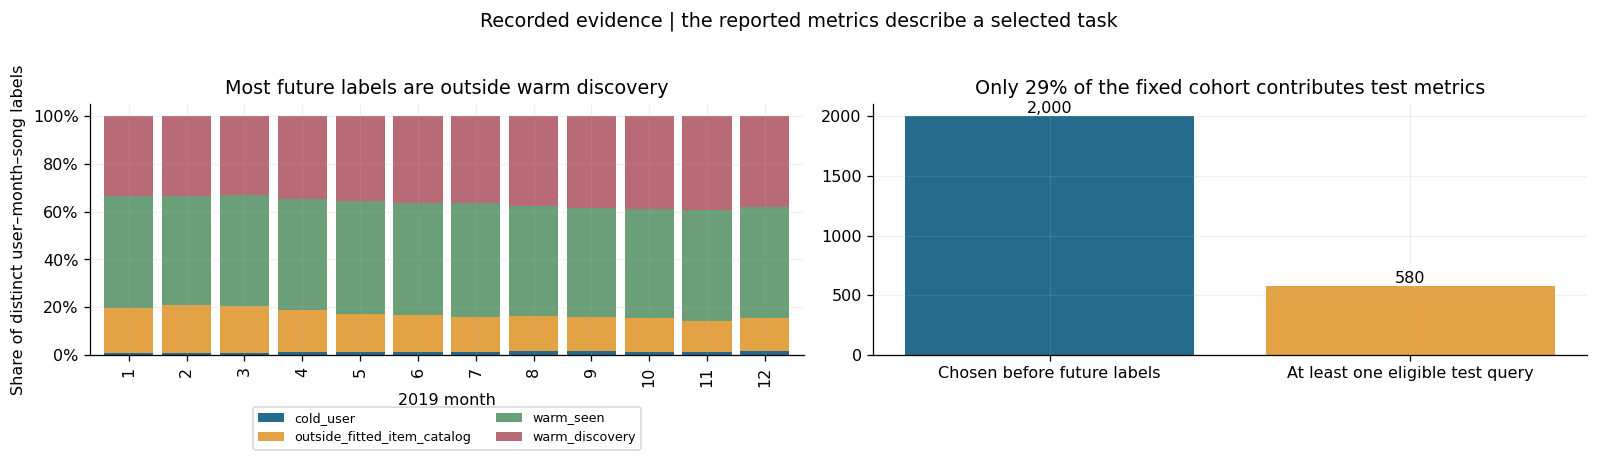

,labels,share
cold_user,12948,0.012921
outside_fitted_item_catalog,161828,0.161487
warm_seen,464639,0.463661
warm_discovery,362694,0.361931


Evaluated cohort labels: 130,090 | user-month queries: 5,312 | unique evaluated users: 580
“Cold user/item” above means absent from fitted vocabularies; filtering and true absence are mixed.


In [ ]:
recorded_coverage=pd.DataFrame({
 'month':range(1,13),
 'cold_user':[959,962,897,1019,1000,1003,985,1378,1292,1105,991,1357],
 'outside_fitted_item_catalog':[16762,17075,17864,15031,14139,13160,12494,12013,11205,11388,9887,10810],
 'warm_seen':[42474,39103,41953,39585,40932,39489,40222,37856,35824,36842,34557,35802],
 'warm_discovery':[30339,28514,30274,29365,30930,30595,30922,30714,30384,31465,29673,29519],
 'evaluated_discovery':[11216,10157,9856,9828,11096,10829,11412,11258,10877,11880,11042,10639]})
cols=['cold_user','outside_fitted_item_catalog','warm_seen','warm_discovery']
shares=recorded_coverage[cols].div(recorded_coverage[cols].sum(axis=1),axis=0)
fig,axes=plt.subplots(1,2,figsize=(14,4))
shares.set_axis(range(1,13)).plot.bar(stacked=True,ax=axes[0],color=COLORS[:4],width=.85)
axes[0].set_xlabel('2019 month'); axes[0].set_ylabel('Share of distinct user–month–song labels')
axes[0].yaxis.set_major_formatter(PercentFormatter(1)); axes[0].legend(fontsize=8,loc='upper center',bbox_to_anchor=(.5,-.18),ncol=2)
axes[0].set_title('Most future labels are outside warm discovery')
cohort=pd.Series({'Chosen before future labels':2000,'At least one eligible test query':580})
axes[1].bar(cohort.index,cohort.values,color=COLORS[:2]); axes[1].set_title('Only 29% of the fixed cohort contributes test metrics')
for j,v in enumerate(cohort.values):axes[1].text(j,v,f'{v:,}',ha='center',va='bottom')
fig.suptitle('Recorded evidence | the reported metrics describe a selected task',y=1.03)
finish('recorded_target_coverage')
totals=recorded_coverage[cols].sum()
display(pd.DataFrame({'labels':totals,'share':totals/totals.sum()}))
print('Evaluated cohort labels:',f'{recorded_coverage.evaluated_discovery.sum():,}',
      '| user-month queries: 5,312 | unique evaluated users: 580')
print('“Cold user/item” above means absent from fitted vocabularies; filtering and true absence are mixed.')


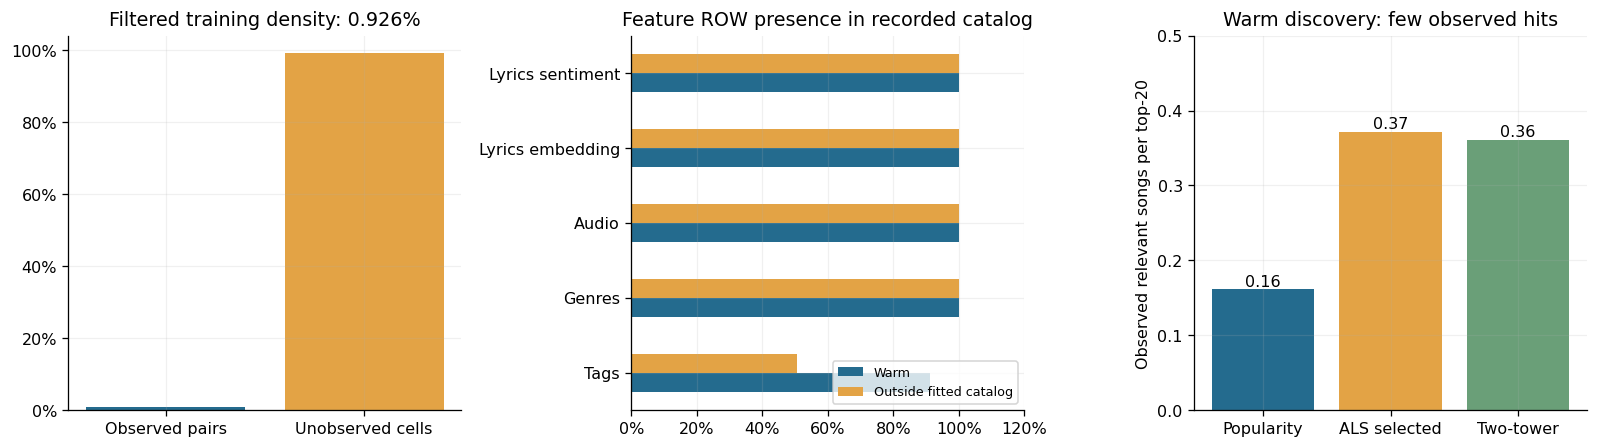

Row presence does not prove nonzero, valid, useful, or historically available features.
Unobserved matrix entries are not known dislikes. These metrics do not measure enjoyment.


In [ ]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
density=2116066/(5463*41834)
axes[0].bar(['Observed pairs','Unobserved cells'],[density,1-density],color=COLORS[:2])
axes[0].yaxis.set_major_formatter(PercentFormatter(1)); axes[0].set_title(f'Filtered training density: {density:.3%}')
coverage=pd.DataFrame({'Warm':[.911723,1,1,1,1],'Outside fitted catalog':[.505788,1,1,1,1]},
    index=['Tags','Genres','Audio','Lyrics embedding','Lyrics sentiment'])
coverage.plot.barh(ax=axes[1],color=COLORS[:2]); axes[1].set_xlim(0,1.2)
axes[1].xaxis.set_major_formatter(PercentFormatter(1)); axes[1].set_title('Feature ROW presence in recorded catalog')
axes[1].legend(fontsize=8,loc='lower right')
metrics=pd.DataFrame({'precision':[.008067,.018571,.018063],
                      'hit_rate':[.119164,.232869,.230610]},index=['Popularity','ALS selected','Two-tower'])
axes[2].bar(metrics.index,20*metrics.precision,color=COLORS[:3]); axes[2].set_ylim(0,.5)
axes[2].set_ylabel('Observed relevant songs per top-20'); axes[2].set_title('Warm discovery: few observed hits')
for j,v in enumerate(20*metrics.precision):axes[2].text(j,v,f'{v:.2f}',ha='center',va='bottom')
finish('recorded_sparsity_features_and_hits')
print('Row presence does not prove nonzero, valid, useful, or historically available features.')
print('Unobserved matrix entries are not known dislikes. These metrics do not measure enjoyment.')


**What these figures already establish:** the evaluation covers a restricted set of future labels and users; many listens repeat known songs; a large feature catalog has no interaction evidence; and tag row coverage differs substantially across the fitted and outside-fitted catalogs. They do **not** establish how much each issue causes the low model scores.

The remaining sections measure these effects directly and distinguish **dataset properties**, **sample effects**, and **protocol choices**. Test-label exploration makes this an exploratory dataset audit. If these findings influence model or protocol choices, reserve another future period for confirmatory evaluation.


## 2. Data contract, configuration, and loading

The authoritative event key is `(user_id, item_id, timestamp)`. Different timestamps for the same song are retained. Exact duplicates are removed globally. Source timestamps without a timezone are interpreted as UTC, matching the existing notebooks.

**Resource expectations:** the timestamp download is about 2.2 GB compressed; scanning still reads all source rows even for a 10% user sample. SQLite stages deduplicated events on disk to bound ingestion RAM; allow several additional GB for tables, indexes, and outputs. This prioritizes a portable dependency footprint over maximum preprocessing speed. Reusing the existing Parquet manifests is faster. Full-population analysis can require substantially more disk and time.

`DATA_MODE='auto'` reuses manifests only when the adjacent original `config.json` matches the requested sampling and years. Otherwise it uses the raw file. Manifests are already sampled: **never sample them again**. The original experiment files are read only; this notebook writes into its own analysis directory.


In [ ]:
ROOT=Path('/content/music4all_onion') if Path('/content').exists() else Path.cwd()/'music4all_onion'
CF_RUN=ROOT/'runs'/'yearly_2014_2017_val2018_test2019_users10pct_v1'
MANIFEST_DIR=CF_RUN/'manifests'
RAW_PATH=ROOT/'raw'/'userid_trackid_timestamp.tsv.bz2'
DATA_MODE='auto'                 # auto, raw, or manifests
DOWNLOAD_IF_MISSING=True
USER_FRACTION=.10; SEED=42
TRAIN_START=2014; TRAIN_END=2017; VAL_YEAR=2018; TEST_YEAR=2019
MIN_USER=5; MIN_ITEM=5; EVAL_LIMIT=2000; K=20
CHUNK_SIZE=250000
FEATURE_MODE='available'          # available, download, or skip
RUN_FEATURE_AUDIT=True            # wide tag tables can take time to decompress/parse
OUT=ROOT/'dataset_analysis'/'users10pct_2014_2019_v1'
OUT.mkdir(parents=True,exist_ok=True)
DB_PATH=OUT/'audit.sqlite'
RECORD='15394646'
EVENT_MD5='dfe82201036765f7463e6f3ce3d0f991'
assert 0<USER_FRACTION<=1 and TRAIN_START<=TRAIN_END<VAL_YEAR<TEST_YEAR
assert DATA_MODE in {'auto','raw','manifests'}
assert FEATURE_MODE in {'available','download','skip'}
assert MIN_USER>=1 and MIN_ITEM>=1 and K>0
print('Analysis outputs:',OUT)
print('Feature audit uses existing files by default; FEATURE_MODE="download" fetches missing feature files.')


Analysis outputs: /content/music4all_onion/dataset_analysis/users10pct_2014_2019_v1
Feature audit uses existing files by default; FEATURE_MODE="download" fetches missing feature files.


In [ ]:
def checksum(path, algorithm='sha256'):
    h=hashlib.new(algorithm)
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def obtain(filename, md5):
    path=ROOT/'raw'/filename; path.parent.mkdir(parents=True,exist_ok=True)
    print(path)
    if path.exists():
        if checksum(path,'md5')!=md5:raise ValueError(f'Checksum mismatch: {path}; resolve before continuing.')
        return path
    part=path.with_name(path.name+'.part')
    print('Downloading',filename)
    req=urllib.request.Request(f'https://zenodo.org/records/{RECORD}/files/{filename}?download=1',
                               headers={'User-Agent':'Music4All-Onion-dataset-audit/1.0'})
    try:
        with urllib.request.urlopen(req,timeout=120) as response,open(part,'wb') as dest:
            shutil.copyfileobj(response,dest,length=8*1024*1024)
        if checksum(part,'md5')!=md5:raise ValueError(f'Checksum mismatch: {filename}')
        part.replace(path)
    except Exception:
        part.unlink(missing_ok=True); raise
    return path
@lru_cache(maxsize=500000)
def retain_user(user_id):
    value=int.from_bytes(hashlib.sha256(f'{SEED}:{user_id}'.encode()).digest()[:8],'big')
    return value<int(USER_FRACTION*2**64)
def stat_signature(path):
    s=path.stat();return {'path':str(path.resolve()),'bytes':s.st_size,'mtime_ns':s.st_mtime_ns}
def manifest_contract():
    p=MANIFEST_DIR.parent/'config.json'
    if not p.exists():return False,'No adjacent config.json; cannot establish sample identity.'
    c=json.loads(p.read_text())
    expected={'seed':SEED,'user_fraction':USER_FRACTION,'train_start_year':TRAIN_START,
              'train_end_year':TRAIN_END,'val_year':VAL_YEAR,'test_year':TEST_YEAR}
    mismatch={k:(c.get(k),v) for k,v in expected.items() if c.get(k)!=v}
    return not mismatch, str(mismatch) if mismatch else 'Matching sampling/calendar configuration.'
manifest_files=sorted(MANIFEST_DIR.glob('split=*/*.parquet'))
contract_ok,contract_note=manifest_contract()
mode='manifests' if DATA_MODE=='manifests' or (DATA_MODE=='auto' and manifest_files and contract_ok) else 'raw'
if mode=='manifests':
    if not contract_ok:raise ValueError('Manifest contract cannot be verified: '+contract_note)
    for split in ['train','val','test']:
        if not list((MANIFEST_DIR/f'split={split}').glob('*.parquet')):raise FileNotFoundError(split)
    try:import pyarrow.parquet as pq
    except ImportError:
        raise ImportError('Manifest reuse requires pyarrow. In Colab run %pip install -q pyarrow, then rerun this cell.')
else:
    if not RAW_PATH.exists() and not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError(f'Provide {RAW_PATH}, verified manifests, or enable DOWNLOAD_IF_MISSING.')
    RAW_PATH=obtain(RAW_PATH.name,EVENT_MD5)
source_files=manifest_files if mode=='manifests' else [RAW_PATH]
CONTRACT={'mode':mode,'seed':SEED,'user_fraction':USER_FRACTION,
          'years':[TRAIN_START,TRAIN_END,VAL_YEAR,TEST_YEAR],
          'source':[stat_signature(p) for p in source_files], 'schema_version':1}
print('Data mode:',mode,'|',contract_note)
print('Manifest mode only audits the retained time window; outside-window cleaning needs the raw source.')

/content/music4all_onion/raw/userid_trackid_timestamp.tsv.bz2
Data mode: raw | No adjacent config.json; cannot establish sample identity.
Manifest mode only audits the retained time window; outside-window cleaning needs the raw source.


In [ ]:
def open_db():
    con=sqlite3.connect(DB_PATH)
    con.execute('PRAGMA temp_store=FILE'); con.execute('PRAGMA cache_size=-131072')
    return con
con=open_db()
def query(sql,params=()):return pd.read_sql_query(sql,con,params=params)
def scalar(sql,params=()):return con.execute(sql,params).fetchone()[0]
def table(frame,name):
    # Controlled, notebook-defined identifiers only.
    frame.to_sql(name,con,if_exists='replace',index=False,chunksize=20000)
def resolve_columns(columns):
    normalized={''.join(ch for ch in str(c).lower() if ch.isalnum()):c for c in columns}
    groups=[['userid','user','listenerid','uid'],['trackid','itemid','songid','musicid','track','song'],
            ['timestamp','datetime','playedat','eventtime','date']]
    names=[next((normalized[k] for k in group if k in normalized),None) for group in groups]
    if None in names:raise ValueError(f'Cannot resolve event columns: {list(columns)}')
    return names
completion=OUT/'INGESTION.json'
if completion.exists():
    saved=json.loads(completion.read_text())
    if saved['contract']!=CONTRACT:raise ValueError('Source/config changed. Choose a new OUT directory; cached results are not reused.')
    if not scalar("SELECT count(*) FROM sqlite_master WHERE type='table' AND name='events'"):
        raise ValueError('Completion metadata exists but events are missing. Choose a new OUT directory.')
    cleaning=saved['cleaning']; full_year_counts=saved.get('full_year_counts',{})
    print('Reusing completed event database.')
else:
    con.execute('DROP TABLE IF EXISTS events')
    con.execute('CREATE TABLE events(user_id TEXT NOT NULL,item_id TEXT NOT NULL,timestamp TEXT NOT NULL,year INTEGER NOT NULL,month INTEGER NOT NULL,ym TEXT NOT NULL,split TEXT NOT NULL,UNIQUE(user_id,item_id,timestamp))')
    con.commit()
    cleaning=dict(source_rows=0,invalid_rows=0,outside_window=0,selected_before_dedup=0)
    full_year_counts={}
    def frames():
        if mode=='raw':
            names=resolve_columns(pd.read_csv(RAW_PATH,sep='\t',compression='bz2',nrows=0).columns)
            yield from pd.read_csv(RAW_PATH,sep='\t',compression='bz2',usecols=names,dtype=str,
                                   keep_default_na=False,chunksize=CHUNK_SIZE)
        else:
            for path in source_files:
                for batch in pq.ParquetFile(path).iter_batches(batch_size=CHUNK_SIZE):yield batch.to_pandas()
    for chunk_no,frame in enumerate(frames(),1):
        uc,ic,tc=resolve_columns(frame.columns)
        df=frame[[uc,ic,tc]].rename(columns={uc:'user_id',ic:'item_id',tc:'timestamp'}).copy()
        cleaning['source_rows']+=len(df)
        df['user_id']=df.user_id.astype('string').str.strip(); df['item_id']=df.item_id.astype('string').str.strip()
        df['timestamp']=pd.to_datetime(df.timestamp,format='mixed',errors='coerce',utc=True)
        valid=(df.user_id.notna() & df.item_id.notna() & df.user_id.ne('') & df.item_id.ne('') & df.timestamp.notna())
        cleaning['invalid_rows']+=int((~valid).sum());df=df.loc[valid].copy()
        df['year']=df.timestamp.dt.year
        for year,count in df.year.value_counts().items():full_year_counts[str(year)]=full_year_counts.get(str(year),0)+int(count)
        inside=df.year.between(TRAIN_START,TRAIN_END)|df.year.isin([VAL_YEAR,TEST_YEAR])
        cleaning['outside_window']+=int((~inside).sum());df=df.loc[inside].copy()
        if mode=='raw':
            selection={u:retain_user(u) for u in df.user_id.unique()};df=df.loc[df.user_id.map(selection)].copy()
        cleaning['selected_before_dedup']+=len(df)
        df['month']=df.timestamp.dt.month;df['ym']=df.timestamp.dt.strftime('%Y-%m')
        df['split']=np.select([df.year.le(TRAIN_END),df.year.eq(VAL_YEAR)],['train','val'],default='test')
        df['timestamp']=df.timestamp.dt.strftime('%Y-%m-%dT%H:%M:%S.%fZ')
        rows=df[['user_id','item_id','timestamp','year','month','ym','split']].itertuples(index=False,name=None)
        with con:con.executemany('INSERT OR IGNORE INTO events VALUES (?,?,?,?,?,?,?)',rows)
        if chunk_no%20==0:print(f'{chunk_no:,} chunks | {cleaning["source_rows"]:,} source rows scanned')
    cleaning['deduplicated_events']=int(scalar('SELECT count(*) FROM events'))
    cleaning['exact_duplicates_removed']=cleaning['selected_before_dedup']-cleaning['deduplicated_events']
    if not cleaning['deduplicated_events']:raise ValueError('No events survived. Check paths, years, and sample fraction.')
    print('Building disk indexes...')
    for cols in ['split,user_id,item_id','ym,user_id,item_id','item_id,split']:
        con.execute(f'CREATE INDEX IF NOT EXISTS idx_{cols.replace(",","_")} ON events({cols})')
    con.commit()
    completion.write_text(json.dumps({'contract':CONTRACT,'cleaning':cleaning,'full_year_counts':full_year_counts},indent=2))
display(pd.Series(cleaning,name='rows').to_frame())
assert scalar('SELECT count(*) FROM events')==cleaning['deduplicated_events']


20 chunks | 5,000,000 source rows scanned
40 chunks | 10,000,000 source rows scanned
60 chunks | 15,000,000 source rows scanned
80 chunks | 20,000,000 source rows scanned
100 chunks | 25,000,000 source rows scanned
120 chunks | 30,000,000 source rows scanned
140 chunks | 35,000,000 source rows scanned
160 chunks | 40,000,000 source rows scanned
180 chunks | 45,000,000 source rows scanned
200 chunks | 50,000,000 source rows scanned
220 chunks | 55,000,000 source rows scanned
240 chunks | 60,000,000 source rows scanned
260 chunks | 65,000,000 source rows scanned
280 chunks | 70,000,000 source rows scanned
300 chunks | 75,000,000 source rows scanned
320 chunks | 80,000,000 source rows scanned
340 chunks | 85,000,000 source rows scanned
360 chunks | 90,000,000 source rows scanned
380 chunks | 95,000,000 source rows scanned
400 chunks | 100,000,000 source rows scanned
420 chunks | 105,000,000 source rows scanned
440 chunks | 110,000,000 source rows scanned
460 chunks | 115,000,000 source ro

,rows
source_rows,252984396
invalid_rows,0
outside_window,125060811
selected_before_dedup,13362394
deduplicated_events,13362376
exact_duplicates_removed,18


## 3. Quality, chronology, and activity intensity

An exact duplicate could be a repeated log entry; a repeat at another timestamp is a legitimate retained event. Extremely dense activity and very short inter-event gaps are **flags**, not proof of bots or errors. Timestamps describe logged behavior; they do not establish exposure, completion, enjoyment, or a song's release date.

The event schema analyzed here has no impression/exposure logs, explicit dislikes, listening duration, release dates, or artist/title fields. These require independently sourced metadata; this notebook does not infer them from timestamps or IDs.


,split,events,users,songs,first_event,last_event
0,test,1794643,1771,51078,2019-01-01T00:00:02.000000Z,2019-12-31T23:59:51.000000Z
1,train,9769411,5933,48037,2014-01-01T00:00:06.000000Z,2017-12-31T23:59:47.000000Z
2,val,1798322,2178,49625,2018-01-01T00:00:06.000000Z,2018-12-31T23:59:48.000000Z


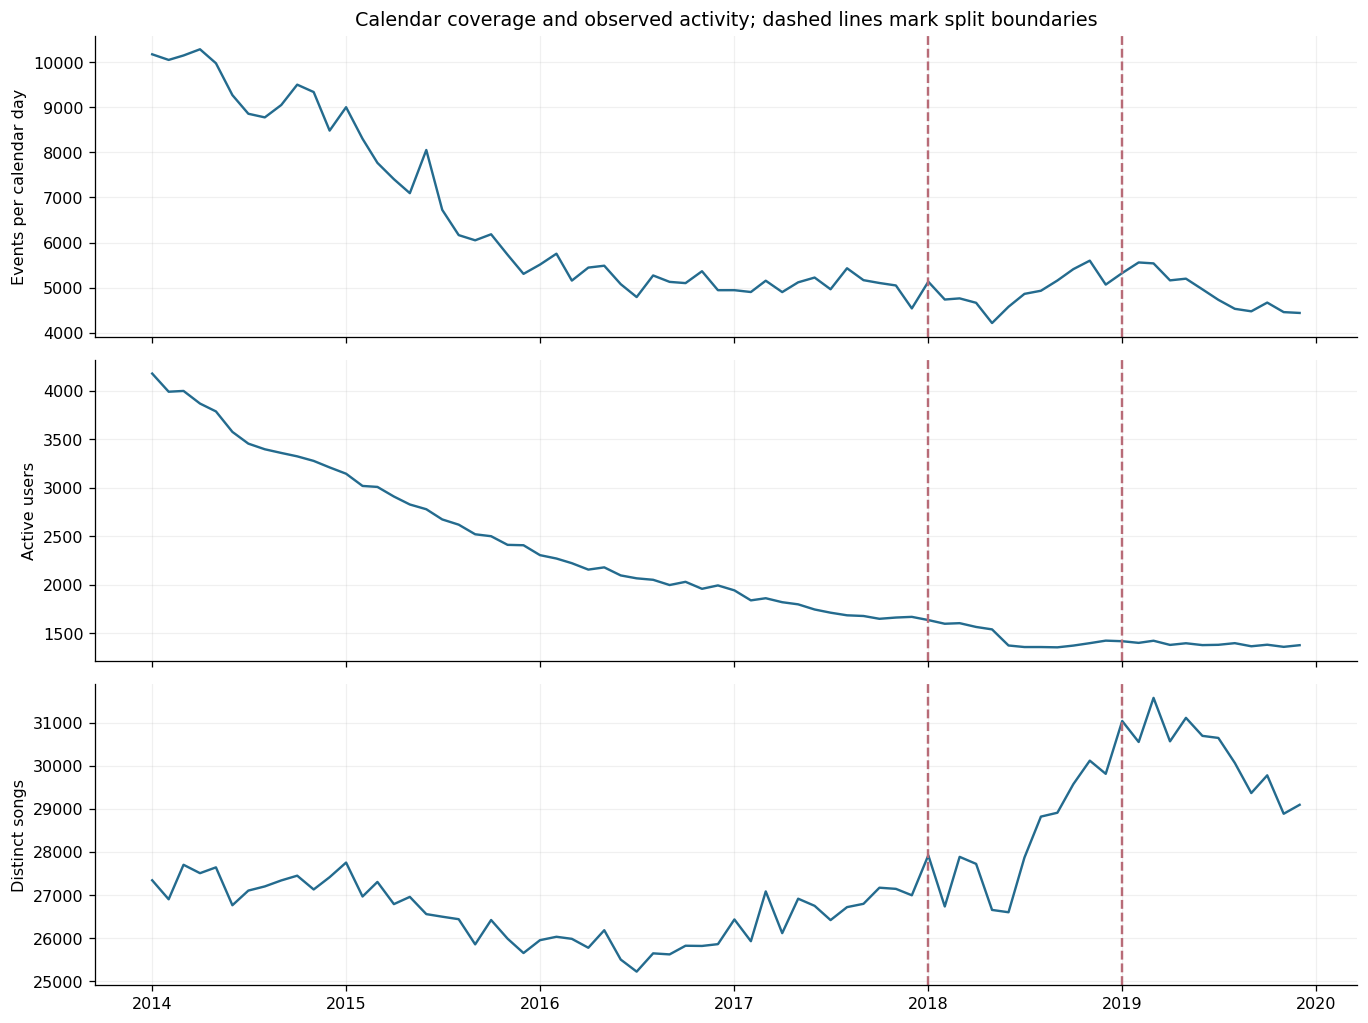

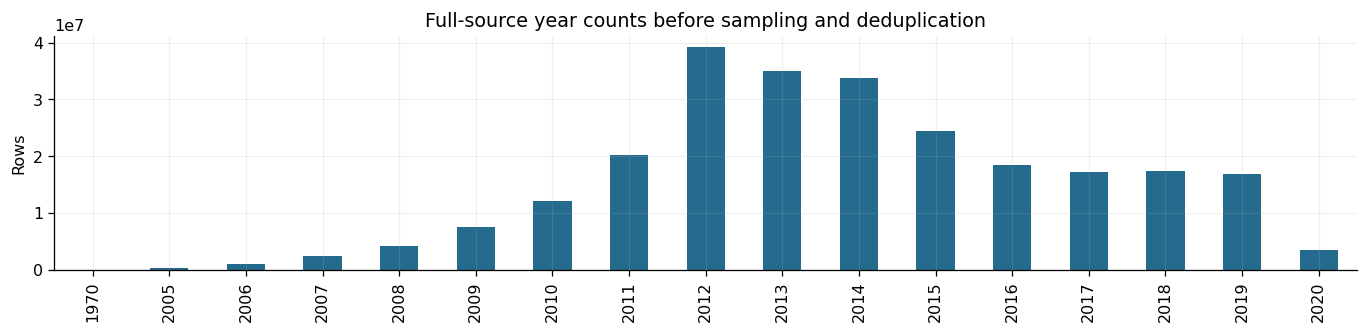

In [ ]:
summary=query('SELECT split,count(*) events,count(DISTINCT user_id) users,count(DISTINCT item_id) songs,min(timestamp) first_event,max(timestamp) last_event FROM events GROUP BY split')
display(summary)
assert set(summary.split)=={'train','val','test'},'All splits must contain events.'
assert scalar("SELECT count(*) FROM events WHERE split='train' AND (year<? OR year>?)",(TRAIN_START,TRAIN_END))==0
assert scalar("SELECT count(*) FROM events WHERE (split='val' AND year!=?) OR (split='test' AND year!=?)",(VAL_YEAR,TEST_YEAR))==0
monthly=query('SELECT ym,year,month,split,count(*) events,count(DISTINCT user_id) users,count(DISTINCT item_id) songs FROM events GROUP BY ym,year,month,split ORDER BY ym')
expected=pd.period_range(f'{TRAIN_START}-01',f'{TEST_YEAR}-12',freq='M').astype(str)
monthly=monthly.set_index('ym').reindex(expected).rename_axis('ym').reset_index()
for col in ['events','users','songs']:monthly[col]=monthly[col].fillna(0).astype(int)
monthly['date']=pd.to_datetime(monthly.ym+'-01',utc=True)
monthly['days']=monthly.date.dt.days_in_month
fig,axes=plt.subplots(3,1,figsize=(12,9),sharex=True)
for ax,col,label in zip(axes,['events','users','songs'],['Events per calendar day','Active users','Distinct songs']):
    y=monthly[col]/monthly.days if col=='events' else monthly[col]
    ax.plot(monthly.date,y);ax.set_ylabel(label)
    for cut in [f'{VAL_YEAR}-01-01',f'{TEST_YEAR}-01-01']:ax.axvline(pd.Timestamp(cut,tz='UTC'),color=COLORS[3],ls='--')
axes[0].set_title('Calendar coverage and observed activity; dashed lines mark split boundaries')
finish('timeline')
if mode=='raw':
    ys=pd.Series(full_year_counts).sort_index()
    ax=ys.plot.bar(figsize=(12,3));ax.set_title('Full-source year counts before sampling and deduplication');ax.set_ylabel('Rows')
    finish('full_source_years')
else:print('Full-source year profile unavailable when reusing windowed manifests.')


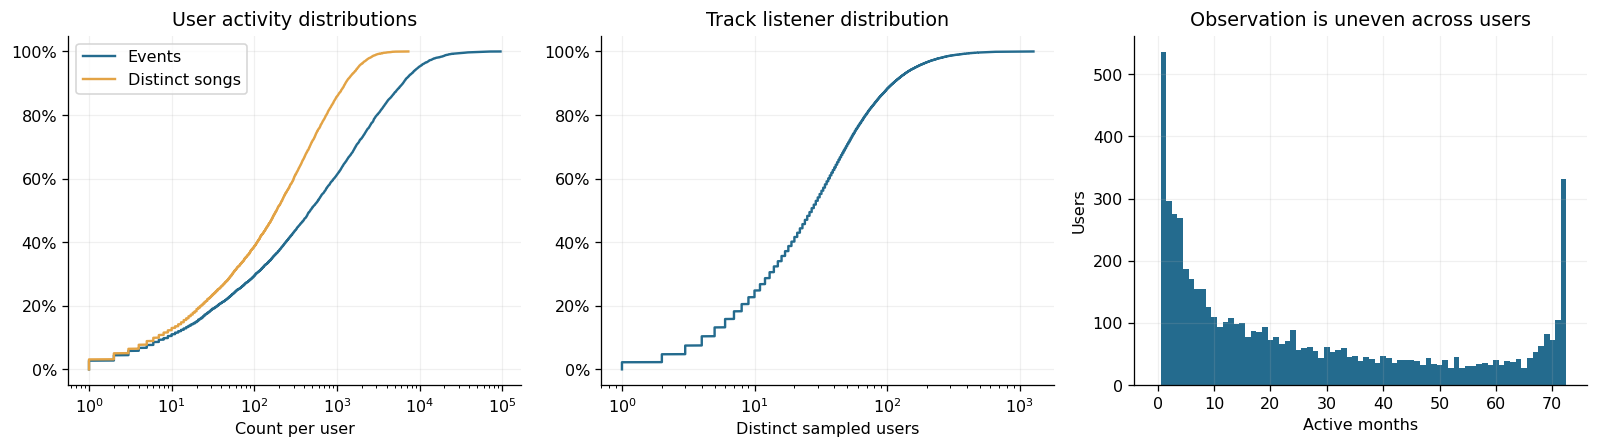

,events,songs,active_months
count,5968.00,5968.00,5968.00
mean,2239.00,450.46,26.29
std,4993.80,657.09,23.99
min,1.00,1.00,1.00
10%,9.00,7.00,2.00
50%,477.50,186.50,18.00
90%,6296.90,1265.00,68.00
99%,22204.85,2977.32,72.00
max,95422.00,7314.00,72.00


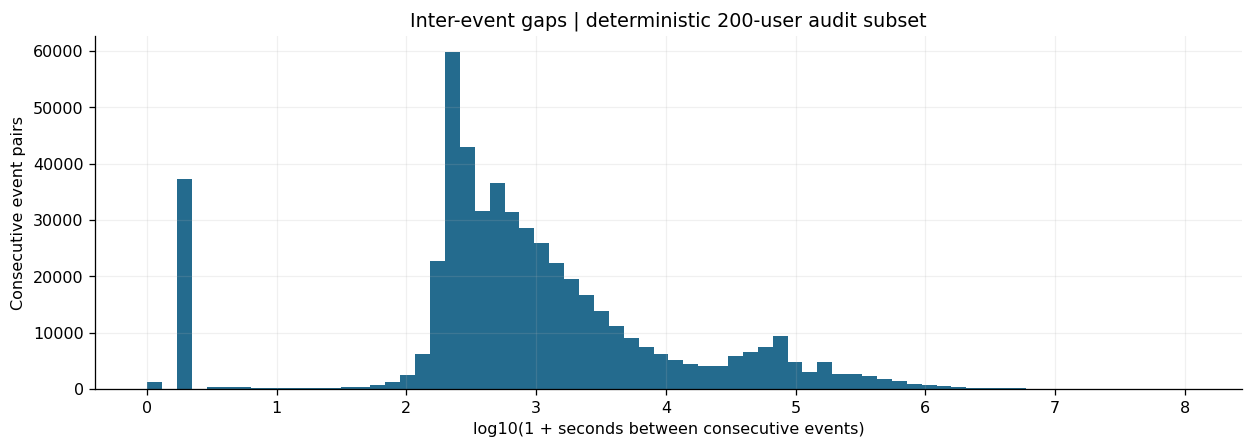

Gap quantiles (seconds): {0.0: 0.0, 0.01: 1.0, 0.1: 147.0, 0.5: 620.0, 0.9: 37817.0, 0.99: 517274.4}


In [ ]:
user_totals=query('SELECT user_id,count(*) events,count(DISTINCT item_id) songs,count(DISTINCT ym) active_months,min(timestamp) first_event,max(timestamp) last_event FROM events GROUP BY user_id')
item_totals=query('SELECT item_id,count(*) events,count(DISTINCT user_id) listeners,count(DISTINCT ym) active_months FROM events GROUP BY item_id')
user_month=query('SELECT user_id,ym,count(*) events,count(DISTINCT item_id) songs FROM events GROUP BY user_id,ym')
fig,axes=plt.subplots(1,3,figsize=(14,4))
ecdf(axes[0],user_totals.events,'Events',True);ecdf(axes[0],user_totals.songs,'Distinct songs',True)
axes[0].set_title('User activity distributions');axes[0].legend();axes[0].set_xlabel('Count per user')
ecdf(axes[1],item_totals.listeners,'Listeners',True);axes[1].set_title('Track listener distribution');axes[1].set_xlabel('Distinct sampled users')
axes[2].hist(user_totals.active_months,bins=np.arange(0,len(expected)+2)-.5,color=COLORS[0]);axes[2].set_xlabel('Active months');axes[2].set_ylabel('Users');axes[2].set_title('Observation is uneven across users')
finish('activity_distributions')
display(user_totals[['events','songs','active_months']].describe(percentiles=[.1,.5,.9,.99]).round(2))
# Gap audit: choose users deterministically, without selecting them for high activity.
gap_users=sorted(user_totals.user_id,key=lambda x:hashlib.sha256(f'{SEED}:{x}'.encode()).hexdigest())[:200]
table(pd.DataFrame({'user_id':gap_users}),'gap_users')
gap_events=query('SELECT e.user_id,e.timestamp FROM events e JOIN gap_users u USING(user_id) ORDER BY e.user_id,e.timestamp')
gap_events['dt']=pd.to_datetime(gap_events.timestamp,utc=True)
gaps=gap_events.groupby('user_id').dt.diff().dt.total_seconds().dropna()
if len(gaps):
    fig,ax=plt.subplots();ax.hist(np.log10(1+gaps.clip(lower=0)),bins=70)
    ax.set_xlabel('log10(1 + seconds between consecutive events)');ax.set_ylabel('Consecutive event pairs')
    ax.set_title(f'Inter-event gaps | deterministic {len(gap_users)}-user audit subset');finish('event_gaps')
    print('Gap quantiles (seconds):',gaps.quantile([0,.01,.1,.5,.9,.99]).round(2).to_dict())
del gap_events


## 4. Sparsity, repeated plays, and popularity concentration

Count **events** and **distinct pairs** separately. Millions of events can be repeated listens on the same sparse support. Density depends on the chosen user and item universe, so report both unfiltered sampled training and the fitted matrix. A concentrated listening distribution makes popularity a necessary reference; it does not establish that popularity is sufficient for individual discovery.


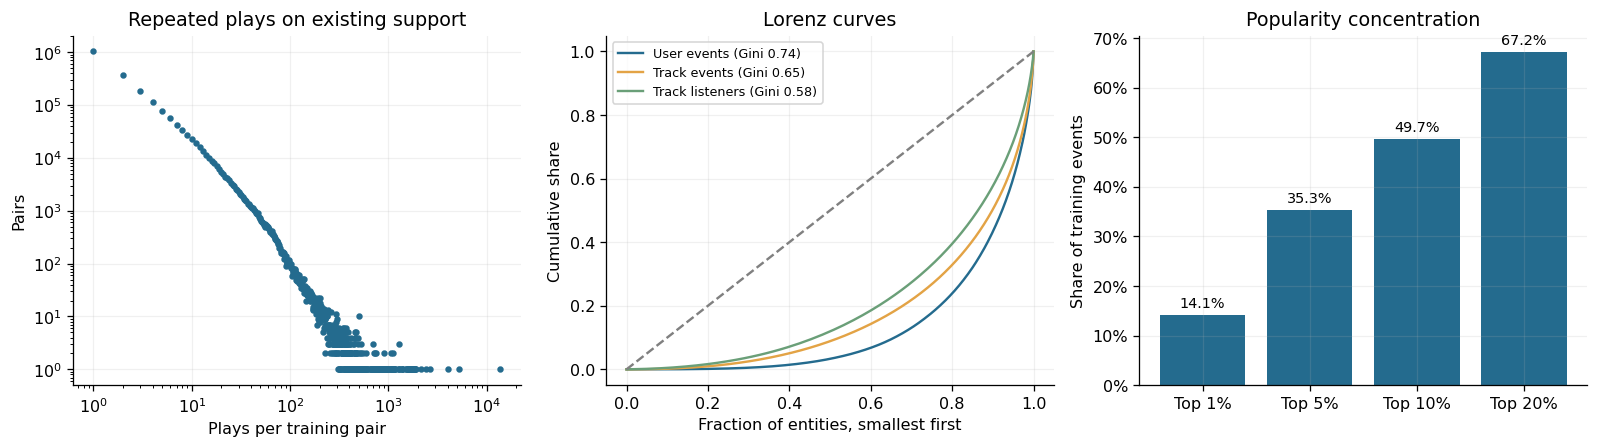

,value
raw_sample_train_users,5.933000e+03
raw_sample_train_items,4.803700e+04
distinct_pairs,2.132298e+06
training_events,9.769411e+06
pair_density,7.481655e-03
events_beyond_one_per_pair,7.637113e+06
fraction_events_beyond_one_per_pair,7.817373e-01


In [ ]:
con.execute('DROP TABLE IF EXISTS raw_train_pairs')
con.execute("CREATE TABLE raw_train_pairs AS SELECT user_id,item_id,count(*) plays FROM events WHERE split='train' GROUP BY user_id,item_id")
con.execute('CREATE INDEX IF NOT EXISTS train_pair_user ON raw_train_pairs(user_id,item_id)')
con.execute('CREATE INDEX IF NOT EXISTS train_pair_item ON raw_train_pairs(item_id)')
con.commit()
train_users=query('SELECT user_id,count(*) degree,sum(plays) events FROM raw_train_pairs GROUP BY user_id ORDER BY user_id')
train_items=query('SELECT item_id,count(*) listeners,sum(plays) events FROM raw_train_pairs GROUP BY item_id ORDER BY item_id')
Nraw=int(scalar('SELECT count(*) FROM raw_train_pairs'))
raw_density=Nraw/(len(train_users)*len(train_items))
pair_hist=query('SELECT plays,count(*) pairs FROM raw_train_pairs GROUP BY plays ORDER BY plays')
fig,axes=plt.subplots(1,3,figsize=(14,4))
axes[0].loglog(pair_hist.plays,pair_hist.pairs,'.');axes[0].set_xlabel('Plays per training pair');axes[0].set_ylabel('Pairs');axes[0].set_title('Repeated plays on existing support')
for values,label in [(train_users.events,'User events'),(train_items.events,'Track events'),(train_items.listeners,'Track listeners')]:
    x=np.sort(np.asarray(values));axes[1].plot(np.arange(len(x)+1)/len(x),np.r_[0,np.cumsum(x)/x.sum()],label=f'{label} (Gini {gini(x):.2f})')
axes[1].plot([0,1],[0,1],ls='--',color='gray');axes[1].legend(fontsize=8);axes[1].set_xlabel('Fraction of entities, smallest first');axes[1].set_ylabel('Cumulative share');axes[1].set_title('Lorenz curves')
head=[]
for pct in [.01,.05,.1,.2]:
    n=max(1,int(np.ceil(pct*len(train_items))))
    head.append(train_items.nlargest(n,'events').events.sum()/train_items.events.sum())
axes[2].bar(['Top 1%','Top 5%','Top 10%','Top 20%'],head);axes[2].set_ylabel('Share of training events');axes[2].yaxis.set_major_formatter(PercentFormatter(1));axes[2].set_title('Popularity concentration');bar_labels(axes[2])
finish('repeat_listening_and_concentration')
display(pd.Series({'raw_sample_train_users':len(train_users),'raw_sample_train_items':len(train_items),
 'distinct_pairs':Nraw,'training_events':int(train_users.events.sum()),'pair_density':raw_density,
 'events_beyond_one_per_pair':int(train_users.events.sum())-Nraw,
 'fraction_events_beyond_one_per_pair':1-Nraw/train_users.events.sum()}).to_frame('value'))


## 5. Cohort activity and catalog first observation

The following heatmaps use a **fixed observed training-user cohort**. Nonappearance means no recorded in-catalog event in that month; it cannot distinguish inactivity on Last.fm, listening outside this catalog, or missing observation. Track first-observation dates are sample-dependent and **are not release dates**. The 2014 left boundary also censors earlier activity.


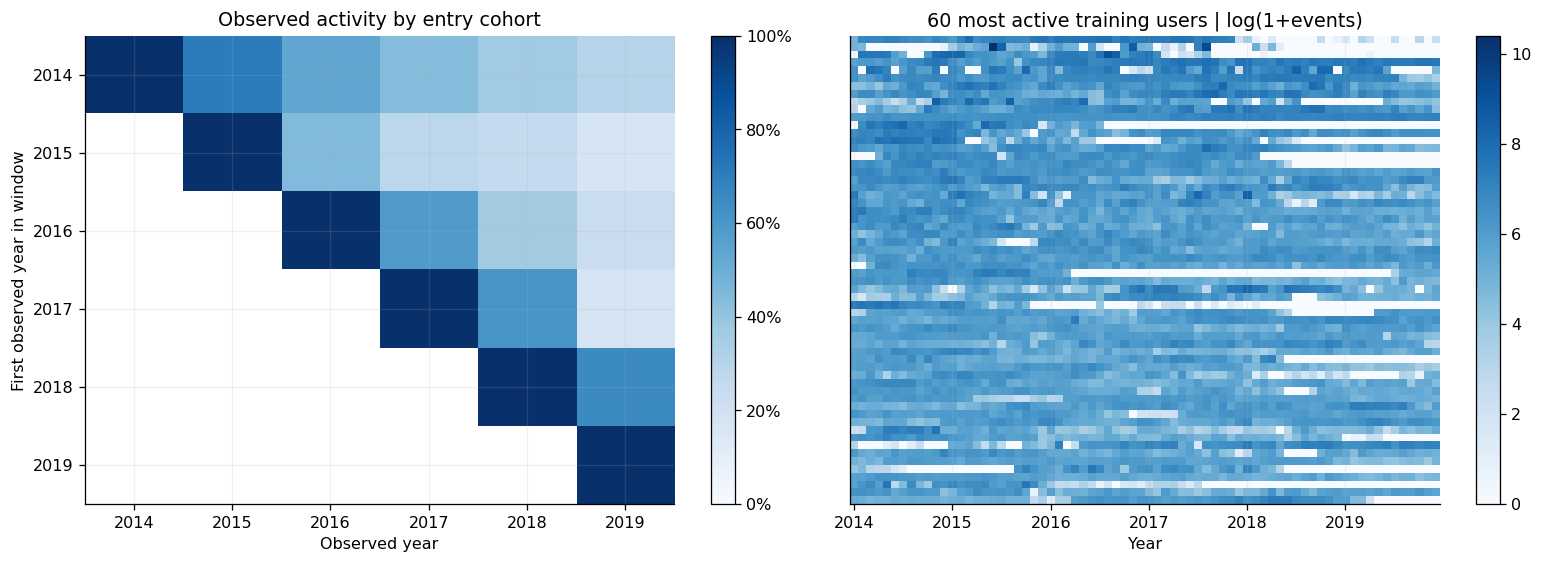

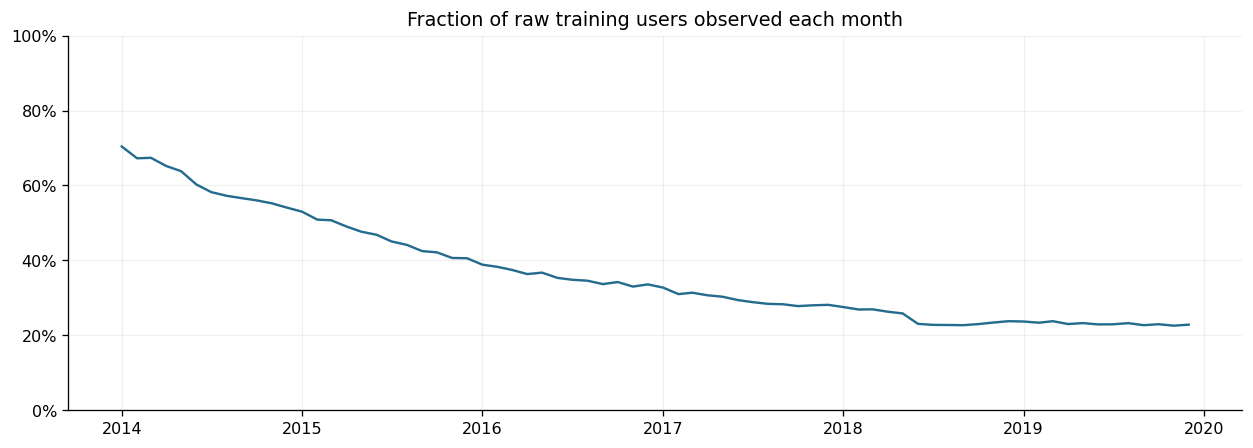

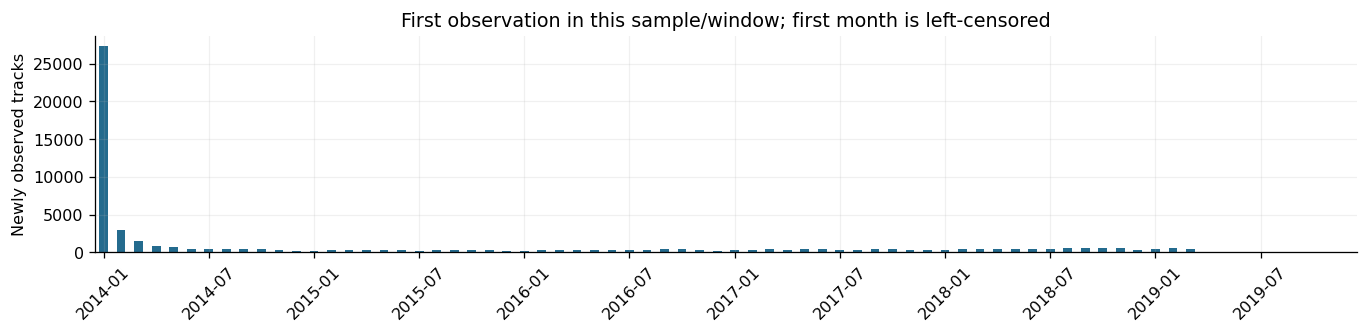

In [ ]:
user_year=query('SELECT user_id,year,count(*) events FROM events GROUP BY user_id,year')
entry=user_year.groupby('user_id').year.min().rename('entry_year')
u_year=user_year.join(entry,on='user_id')
cohorts=u_year.groupby(['entry_year','year']).user_id.nunique().unstack().reindex(columns=range(TRAIN_START,TEST_YEAR+1))
cohort_size=entry.value_counts();cohort_frac=cohorts.div(cohort_size,axis=0)
for first in cohort_frac.index:
    cohort_frac.loc[first,cohort_frac.columns<first]=np.nan
retention=user_month[user_month.user_id.isin(set(train_users.user_id))].groupby('ym').user_id.nunique().reindex(expected,fill_value=0)/len(train_users)
# Select largest histories from TRAIN only to make a legible illustrative matrix.
chosen=train_users.nlargest(60,'events').user_id
activity=user_month[user_month.user_id.isin(chosen)].pivot(index='user_id',columns='ym',values='events').reindex(index=chosen,columns=expected).fillna(0)
fig,axes=plt.subplots(1,2,figsize=(14,5))
im=axes[0].imshow(cohort_frac,aspect='auto',vmin=0,vmax=1,cmap='Blues')
axes[0].set_xticks(range(len(cohort_frac.columns)),cohort_frac.columns);axes[0].set_yticks(range(len(cohort_frac.index)),cohort_frac.index)
axes[0].set_xlabel('Observed year');axes[0].set_ylabel('First observed year in window');axes[0].set_title('Observed activity by entry cohort');fig.colorbar(im,ax=axes[0],format=PercentFormatter(1))
im2=axes[1].imshow(np.log1p(activity),aspect='auto',cmap='Blues');axes[1].set_yticks([])
axes[1].set_xticks(np.arange(0,len(expected),12),[x[:4] for x in expected[::12]])
axes[1].set_title('60 most active training users | log(1+events)');axes[1].set_xlabel('Year');fig.colorbar(im2,ax=axes[1])
finish('cohort_heatmaps')
fig,ax=plt.subplots();ax.plot(pd.to_datetime(retention.index),retention.values)
ax.set_ylim(0,1);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_title('Fraction of raw training users observed each month')
finish('fixed_cohort_activity')
first_items=query('SELECT item_id,min(ym) first_ym FROM events GROUP BY item_id')
new_tracks=first_items.groupby('first_ym').size().reindex(expected,fill_value=0)
ax=new_tracks.plot.bar(figsize=(12,3));ax.set_xticks(np.arange(0,len(expected),6),expected[::6],rotation=45);ax.set_ylabel('Newly observed tracks');ax.set_title('First observation in this sample/window; first month is left-censored')
finish('catalog_first_observation')


## 6. Reproduce filtering and decompose future-label coverage

The original pipeline keeps users with at least five distinct training songs, then songs with at least five retained listeners, then removes users with no remaining pairs. This is **one pass**, not a k-core: a final user can have fewer than five songs.

We distinguish three item groups: **warm fitted**, **observed in sampled raw training but filtered**, and **unobserved in sampled training window**. The last group may have interactions from unsampled users or before 2014. It does not establish a globally new song.

All target counts below are **distinct user–month–song labels**, not events. A disjoint coverage decomposition assigns unknown users first. A separate cross-tab keeps user and item scope visible rather than concealing item status behind user exclusions.


In [ ]:
con.execute('DROP TABLE IF EXISTS fit_pairs')
con.execute('CREATE TABLE fit_pairs AS WITH ru AS (SELECT user_id FROM raw_train_pairs GROUP BY user_id HAVING count(*)>=?), ri AS (SELECT p.item_id FROM raw_train_pairs p JOIN ru USING(user_id) GROUP BY p.item_id HAVING count(*)>=?) SELECT p.* FROM raw_train_pairs p JOIN ru USING(user_id) JOIN ri USING(item_id)',(MIN_USER,MIN_ITEM))
con.execute('CREATE INDEX IF NOT EXISTS fit_pair_user ON fit_pairs(user_id,item_id)')
con.execute('CREATE INDEX IF NOT EXISTS fit_pair_item ON fit_pairs(item_id)')
fit_users=query('SELECT user_id,count(*) degree,sum(plays) events FROM fit_pairs GROUP BY user_id ORDER BY user_id')
fit_items=query('SELECT item_id,count(*) listeners,sum(plays) events FROM fit_pairs GROUP BY item_id ORDER BY item_id')
if fit_users.empty or fit_items.empty:raise ValueError('No pairs survive; lower thresholds or increase user sample.')
table(fit_users[['user_id']],'fit_users');table(fit_items[['item_id']],'fit_items')
table(train_users[['user_id']],'raw_train_users');table(train_items[['item_id']],'raw_train_items')
nfit=int(scalar('SELECT count(*) FROM fit_pairs'))
density_table=pd.DataFrame({'users':[len(train_users),len(fit_users)],'songs':[len(train_items),len(fit_items)],'pairs':[Nraw,nfit]},index=['Sampled raw training','Fitted training'])
density_table['density']=density_table.pairs/(density_table.users*density_table.songs)
display(density_table); print('Final users below initial user threshold:',int((fit_users.degree<MIN_USER).sum()))
# Match original sorted training user indices and RNG; prefer saved cohort when available.
cohort_file=CF_RUN/'model_data'/'eval_user_indices.npy'
user_map_file=CF_RUN/'model_data'/'users.parquet'
if cohort_file.exists() and user_map_file.exists() and mode=='manifests':
    original_map=pd.read_parquet(user_map_file).sort_values('user_index')
    if original_map.user_id.astype(str).tolist()!=fit_users.user_id.astype(str).tolist():raise ValueError('Saved cohort vocabulary differs from reconstructed fit users.')
    ix=np.load(cohort_file)
    if np.any(ix<0) or np.any(ix>=len(fit_users)):raise ValueError('Saved cohort indices are invalid.')
    cohort=fit_users.iloc[ix].user_id.tolist();cohort_origin='saved original indices'
else:
    rng=np.random.default_rng(SEED)
    ix=np.arange(len(fit_users)) if EVAL_LIMIT is None or EVAL_LIMIT>=len(fit_users) else np.sort(rng.choice(len(fit_users),EVAL_LIMIT,replace=False))
    cohort=fit_users.iloc[ix].user_id.tolist();cohort_origin='reconstructed with original sorted-ID rule'
table(pd.DataFrame({'user_id':cohort}),'eval_users')
print('Evaluation cohort:',len(cohort),'|',cohort_origin)


,users,songs,pairs,density
Sampled raw training,5933,48037,2132298,0.007482
Fitted training,5463,41834,2116066,0.009259


Final users below initial user threshold: 2
Evaluation cohort: 2000 | reconstructed with original sorted-ID rule


item_status                   filtered train item  no sampled train item  \
split user_status                                                          
test  filtered training user                 15.0                   87.0   
      fitted user                         19127.0               142701.0   
      no sampled train user                 313.0                 2373.0   
val   filtered training user                  5.0                    9.0   
      fitted user                         19031.0               106338.0   
      no sampled train user                  93.0                  585.0   

item_status                   warm fitted  
split user_status                          
test  filtered training user       1622.0  
      fitted user                827333.0  
      no sampled train user        8538.0  
val   filtered training user        199.0  
      fitted user                820490.0  
      no sampled train user        3201.0

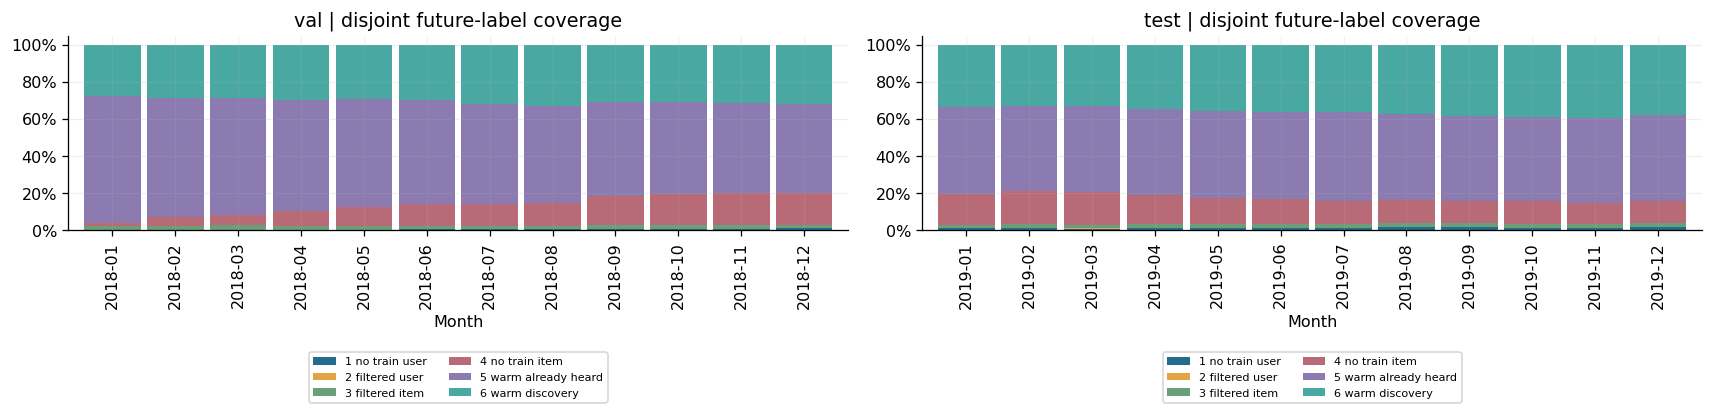

,split,item_status,seen_raw,labels
0,test,filtered train item,0,15364
1,test,filtered train item,1,3763
2,test,no sampled train item,0,142701
3,val,filtered train item,0,13222
4,val,filtered train item,1,5809
5,val,no sampled train item,0,106338


Filtered items can already be in a user’s raw history. This makes outside-fitted-catalog ≠ novel-to-user.


In [ ]:
con.execute('DROP TABLE IF EXISTS labels')
con.execute("""CREATE TABLE labels AS
 WITH future AS (SELECT DISTINCT split,ym,month,user_id,item_id FROM events WHERE split!='train')
 SELECT f.*, CASE WHEN u.user_id IS NOT NULL THEN 'fitted user'
                 WHEN ru.user_id IS NOT NULL THEN 'filtered training user' ELSE 'no sampled train user' END user_status,
        CASE WHEN i.item_id IS NOT NULL THEN 'warm fitted'
             WHEN ri.item_id IS NOT NULL THEN 'filtered train item' ELSE 'no sampled train item' END item_status,
        (p.user_id IS NOT NULL) seen_raw, (fp.user_id IS NOT NULL) seen_fit,
        (eu.user_id IS NOT NULL) in_cohort
 FROM future f LEFT JOIN fit_users u USING(user_id) LEFT JOIN raw_train_users ru USING(user_id)
 LEFT JOIN fit_items i USING(item_id) LEFT JOIN raw_train_items ri USING(item_id)
 LEFT JOIN raw_train_pairs p ON p.user_id=f.user_id AND p.item_id=f.item_id
 LEFT JOIN fit_pairs fp ON fp.user_id=f.user_id AND fp.item_id=f.item_id
 LEFT JOIN eval_users eu USING(user_id)""")
con.execute('CREATE INDEX IF NOT EXISTS label_user_month ON labels(user_id,ym)');con.commit()
coverage_cross=query('SELECT split,user_status,item_status,count(*) labels FROM labels GROUP BY split,user_status,item_status')
display(coverage_cross.pivot_table(index=['split','user_status'],columns='item_status',values='labels',fill_value=0))
CATEGORY="""CASE WHEN user_status='no sampled train user' THEN '1 no train user'
 WHEN user_status='filtered training user' THEN '2 filtered user'
 WHEN item_status='filtered train item' THEN '3 filtered item'
 WHEN item_status='no sampled train item' THEN '4 no train item'
 WHEN seen_raw=1 THEN '5 warm already heard' ELSE '6 warm discovery' END"""
coverage=query(f'SELECT split,ym,{CATEGORY} category,count(*) labels FROM labels GROUP BY split,ym,category')
fig,axes=plt.subplots(1,2,figsize=(15,5))
for ax,split in zip(axes,['val','test']):
    p=coverage[coverage.split.eq(split)].pivot(index='ym',columns='category',values='labels').fillna(0)
    p.div(p.sum(axis=1),axis=0).plot.bar(stacked=True,ax=ax,width=.9)
    ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_title(split+' | disjoint future-label coverage');ax.set_xlabel('Month');ax.legend(fontsize=7,loc='upper center',bbox_to_anchor=(.5,-.60),ncol=2)
finish('future_label_decomposition')
seen_outside=query("SELECT split,item_status,seen_raw,count(*) labels FROM labels WHERE user_status='fitted user' AND item_status!='warm fitted' GROUP BY split,item_status,seen_raw")
display(seen_outside)
print('Filtered items can already be in a user’s raw history. This makes outside-fitted-catalog ≠ novel-to-user.')


,year,chosen_users,possible_user_months,observed_user_months,warm_eligible_user_months,warm_eligible_users,strict_combined_eligible_user_months
0,2018,2000,24000,6285,5573,744,5801
1,2019,2000,24000,5813,5312,580,5535


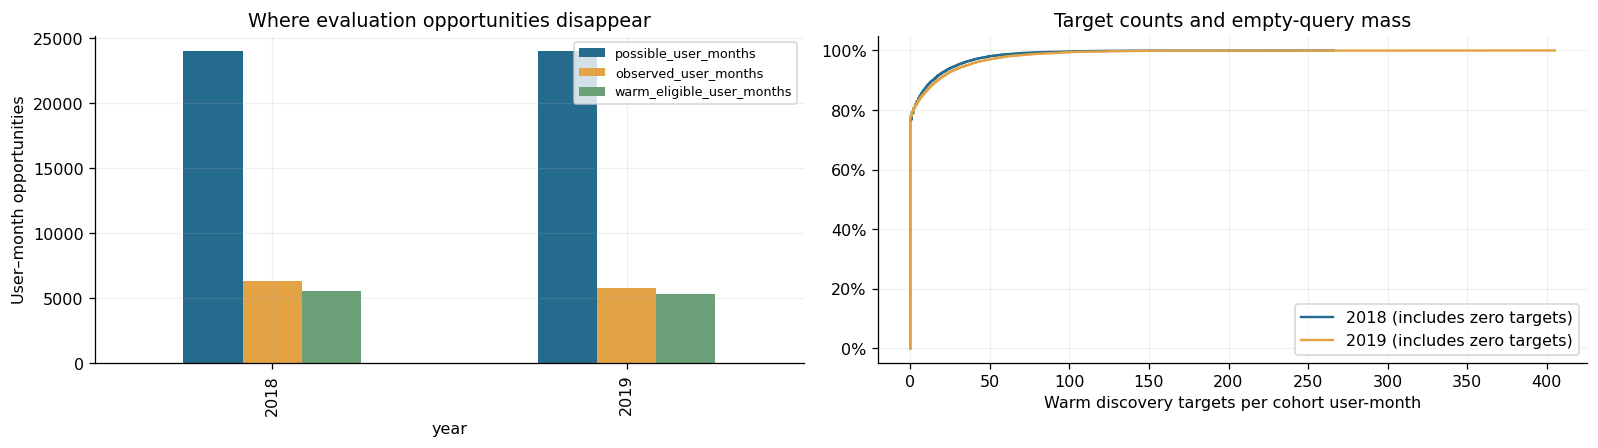

Report cohort participation separately from conditional ranking accuracy. Missing labels are not measured failures.


In [ ]:
# Include zero-target user-months in the cohort coverage audit, while retaining the original conditional metric definition.
future_months=[str(p) for y in [VAL_YEAR,TEST_YEAR] for p in pd.period_range(f'{y}-01',f'{y}-12',freq='M')]
grid=pd.MultiIndex.from_product([cohort,future_months],names=['user_id','ym']).to_frame(index=False)
table(grid,'cohort_grid')
queries=query("""SELECT g.user_id,g.ym,substr(g.ym,1,4) year,
 count(l.item_id) any_labels,
 sum(CASE WHEN l.item_status='warm fitted' AND l.seen_raw=0 THEN 1 ELSE 0 END) warm_targets,
 sum(CASE WHEN l.seen_raw=0 THEN 1 ELSE 0 END) strict_combined_targets,
 sum(CASE WHEN l.item_status!='warm fitted' AND l.seen_fit=0 THEN 1 ELSE 0 END) original_cold_targets,
 sum(CASE WHEN l.item_status!='warm fitted' AND l.seen_raw=0 THEN 1 ELSE 0 END) strict_cold_targets
 FROM cohort_grid g LEFT JOIN labels l ON l.user_id=g.user_id AND l.ym=g.ym GROUP BY g.user_id,g.ym""")
queries['year']=queries.year.astype(int)
funnel=[]
for y,g in queries.groupby('year'):
    funnel.append({'year':y,'chosen_users':len(cohort),'possible_user_months':len(g),'observed_user_months':int(g.any_labels.gt(0).sum()),
        'warm_eligible_user_months':int(g.warm_targets.gt(0).sum()),'warm_eligible_users':g.loc[g.warm_targets.gt(0),'user_id'].nunique(),
        'strict_combined_eligible_user_months':int(g.strict_combined_targets.gt(0).sum())})
funnel=pd.DataFrame(funnel);display(funnel)
fig,axes=plt.subplots(1,2,figsize=(14,4))
funnel.set_index('year')[['possible_user_months','observed_user_months','warm_eligible_user_months']].plot.bar(ax=axes[0],color=COLORS[:3]);axes[0].legend(fontsize=8);axes[0].set_ylabel('User–month opportunities');axes[0].set_title('Where evaluation opportunities disappear')
for y,g in queries.groupby('year'):ecdf(axes[1],g.warm_targets,f'{y} (includes zero targets)')
axes[1].set_xlabel('Warm discovery targets per cohort user-month');axes[1].set_title('Target counts and empty-query mass');axes[1].legend()
finish('evaluation_funnel')
# A zero-target query has undefined recall/NDCG: do not assign it a zero to inflate a headline denominator.
print('Report cohort participation separately from conditional ranking accuracy. Missing labels are not measured failures.')


## 7. Frozen monthly discovery versus annual and rolling-history targets

The frozen model estimates preferences from 2014–2017. The test asks **which not-previously-heard songs will be observed in each month of 2019**, 12–24 months after the cutoff. A static score vector yields the same list every month if the catalog and mask stay fixed.

Here, “rolling” changes only the history mask: at month start it excludes any song heard in earlier observed months, including validation. It does **not** retrain a model. All variants below use the same fitted warm candidate catalog to isolate target/mask definitions. A real rolling benchmark must additionally define catalog availability and update model fitting using past-only data.

Annual discovery removes month timing from relevance. It changes query and target denominators, so a better annual score alone would not establish a better recommender.


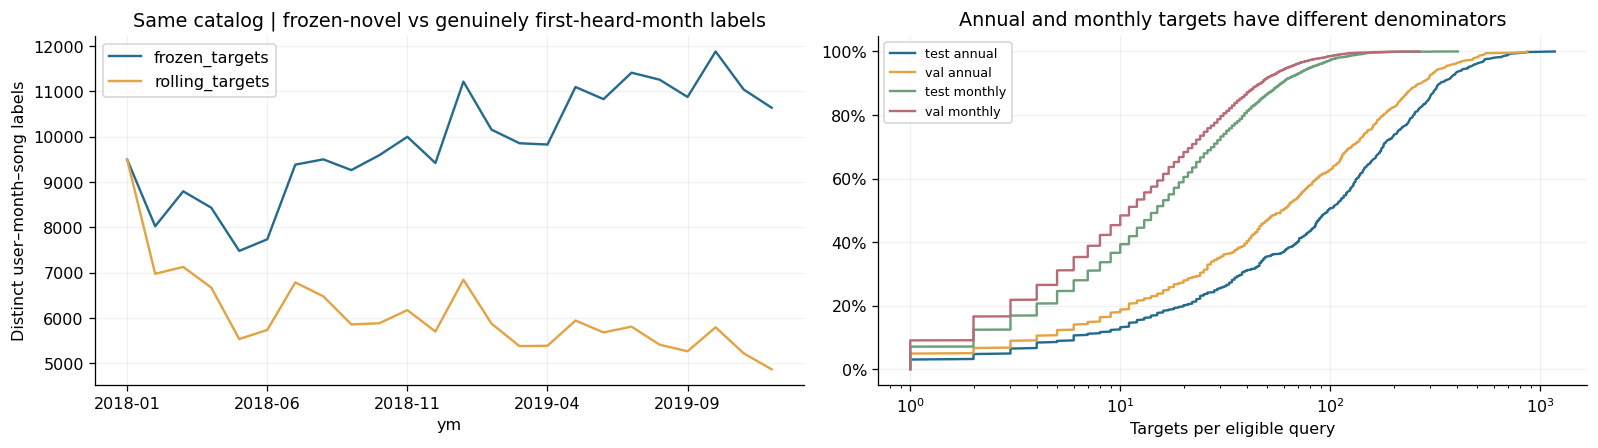

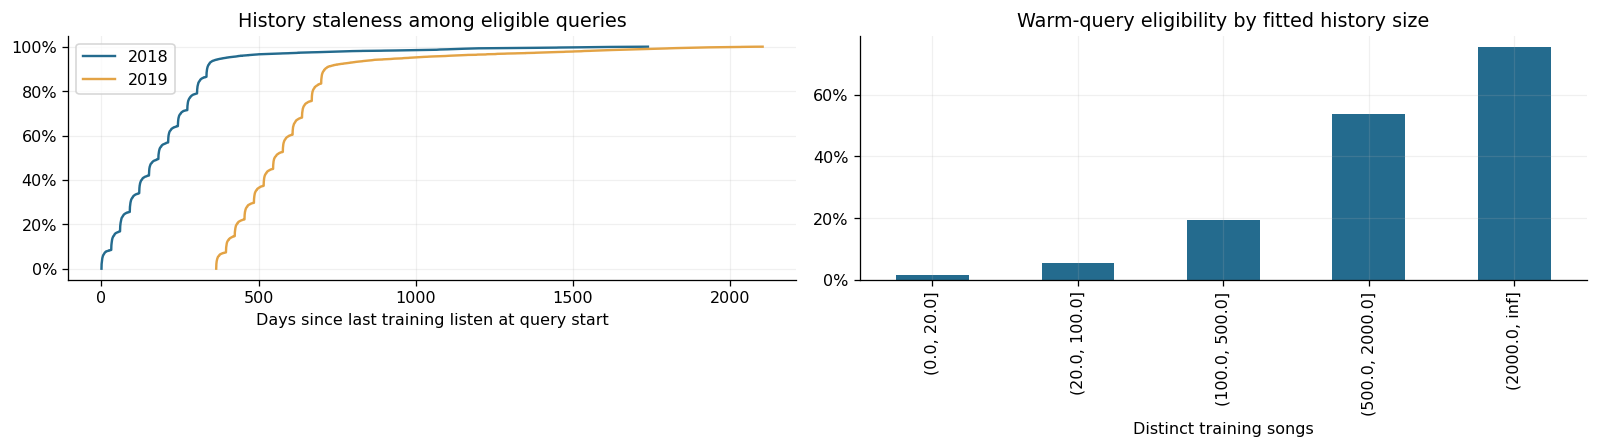

,queries,participation,mean_targets
history_bin,,,
"(0.0, 20.0]",6000,0.014833,0.195000
"(20.0, 100.0]",11256,0.053305,1.226812
"(100.0, 500.0]",19032,0.193569,3.334647
"(500.0, 2000.0]",10752,0.538411,12.038690
"(2000.0, inf]",960,0.753125,30.561458


In [ ]:
con.execute('DROP TABLE IF EXISTS first_pair_month')
con.execute('CREATE TABLE first_pair_month AS SELECT user_id,item_id,min(ym) first_ym FROM events GROUP BY user_id,item_id')
con.execute('CREATE INDEX IF NOT EXISTS first_pair_key ON first_pair_month(user_id,item_id)');con.commit()
temporal=query("""SELECT l.user_id,l.ym,l.split,
 sum(CASE WHEN l.item_status='warm fitted' AND l.seen_raw=0 THEN 1 ELSE 0 END) frozen_targets,
 sum(CASE WHEN l.item_status='warm fitted' AND f.first_ym=l.ym THEN 1 ELSE 0 END) rolling_targets
 FROM labels l JOIN first_pair_month f USING(user_id,item_id) WHERE l.in_cohort=1 GROUP BY l.user_id,l.ym,l.split""")
annual=query("SELECT user_id,split,count(DISTINCT item_id) targets FROM labels WHERE in_cohort=1 AND item_status='warm fitted' AND seen_raw=0 GROUP BY user_id,split")
fig,axes=plt.subplots(1,2,figsize=(14,4))
p=temporal.groupby('ym')[['frozen_targets','rolling_targets']].sum();p.plot(ax=axes[0]);axes[0].set_title('Same catalog | frozen-novel vs genuinely first-heard-month labels');axes[0].set_ylabel('Distinct user–month–song labels')
for split,g in annual.groupby('split'):ecdf(axes[1],g.targets,split+' annual')
for split,g in temporal.groupby('split'):ecdf(axes[1],g.loc[g.frozen_targets.gt(0),'frozen_targets'],split+' monthly')
axes[1].set_xscale('log');axes[1].set_xlabel('Targets per eligible query');axes[1].legend(fontsize=8);axes[1].set_title('Annual and monthly targets have different denominators')
finish('temporal_task_definitions')
# Age of the most recent observed TRAINING listen at the start of each query month.
last_train=query("SELECT user_id,max(timestamp) last_train FROM events WHERE split='train' GROUP BY user_id")
qage=queries.merge(last_train,on='user_id',how='left').merge(fit_users[['user_id','degree']],on='user_id')
qage['age_days']=(pd.to_datetime(qage.ym+'-01',utc=True)-pd.to_datetime(qage.last_train,utc=True)).dt.total_seconds()/86400
fig,axes=plt.subplots(1,2,figsize=(14,4))
for y,g in qage[qage.warm_targets.gt(0)].groupby('year'):ecdf(axes[0],g.age_days,str(y))
axes[0].set_xlabel('Days since last training listen at query start');axes[0].legend();axes[0].set_title('History staleness among eligible queries')
qage['history_bin']=pd.cut(qage.degree,[0,20,100,500,2000,np.inf],right=True)
history=qage.groupby('history_bin',observed=True).agg(queries=('user_id','size'),participation=('warm_targets',lambda x:x.gt(0).mean()),mean_targets=('warm_targets','mean'))
history.participation.plot.bar(ax=axes[1]);axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].set_title('Warm-query eligibility by fitted history size');axes[1].set_xlabel('Distinct training songs')
finish('staleness_and_history');display(history)


## 8. Difficulty reference points and ceilings

For a particular eligible warm query, let $N$ be the candidate count **after masking**, $R$ its relevant-song count, and $k=\min(K,N)$. Under a uniform random ranking without replacement:

- $E[\mathrm{hits}]=kR/N$ and $E[\mathrm{Precision@K}]=kR/(NK)$, using a fixed $K$ denominator.
- $E[\mathrm{Recall@K}]=k/N$.
- $P(\text{any hit})=1-\binom{N-R}{k}/\binom{N}{k}$.
- Expected DCG is $(R/N)\sum_{r=1}^{k}1/\log_2(r+1)$; divide by that query’s ideal DCG for expected NDCG.

The recall ceiling $\min(k,R)/R$ expresses list capacity; it is not an estimate of achievable model quality. These calculations say how difficult **random retrieval** is. They do not make a weak model satisfactory. We use the same query set for each average, and also report user-macro averages.


,random_precision,random_recall,random_hitrate,random_ndcg,recall_capacity_ceiling
query-average by year,,,,,
2018,0.000472,0.000488,0.009332,0.000562,0.860908
2019,0.000600,0.000488,0.011833,0.000676,0.814011


,random_precision,random_recall,random_hitrate,random_ndcg,recall_capacity_ceiling
user-macro by year,,,,,
2018,0.000388,0.000486,0.007674,0.000491,0.892124
2019,0.000505,0.000487,0.009964,0.000595,0.849475


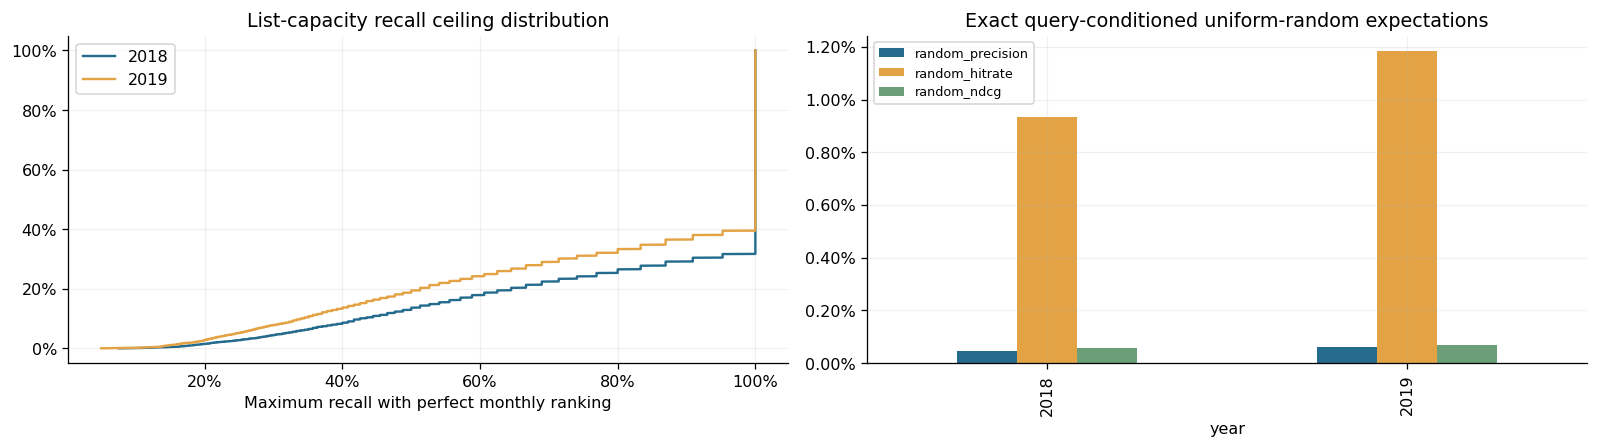

In [ ]:
q=queries[queries.warm_targets.gt(0)].merge(fit_users[['user_id','degree']],on='user_id').copy()
q['N']=len(fit_items)-q.degree;q['R']=q.warm_targets;q['k']=np.minimum(K,q.N)
assert (q.N>=q.R).all() and (q.N>0).all()
q['random_precision']=q.k*q.R/q.N/K
q['random_recall']=q.k/q.N
# Stable product for the no-hit probability; handles impossible zero-hit events exactly.
nohit=np.ones(len(q))
for r in range(K):
    active=r<q.k.to_numpy()
    ratio=np.maximum(q.N.to_numpy()-q.R.to_numpy()-r,0)/np.maximum(q.N.to_numpy()-r,1)
    nohit*=np.where(active,ratio,1)
q['random_hitrate']=1-nohit
weights=1/np.log2(np.arange(1,K+1)+1);discount=np.r_[0,weights.cumsum()]
q['random_ndcg']=(q.R/q.N)*discount[q.k.to_numpy(dtype=int)]/discount[np.minimum(q.R,K).to_numpy(dtype=int)]
q['recall_capacity_ceiling']=np.minimum(q.k,q.R)/q.R
q['precision_capacity_ceiling']=np.minimum(q.k,q.R)/K
metrics=['random_precision','random_recall','random_hitrate','random_ndcg','recall_capacity_ceiling']
reference=q.groupby('year')[metrics].mean()
user_macro=q.groupby(['year','user_id'])[metrics].mean().groupby('year').mean()
display(reference.rename_axis('query-average by year'));display(user_macro.rename_axis('user-macro by year'))
fig,axes=plt.subplots(1,2,figsize=(14,4))
for y,g in q.groupby('year'):ecdf(axes[0],g.recall_capacity_ceiling,str(y))
axes[0].xaxis.set_major_formatter(PercentFormatter(1));axes[0].set_title('List-capacity recall ceiling distribution');axes[0].set_xlabel('Maximum recall with perfect monthly ranking');axes[0].legend()
reference[['random_precision','random_hitrate','random_ndcg']].plot.bar(ax=axes[1]);axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].set_title('Exact query-conditioned uniform-random expectations');axes[1].legend(fontsize=8)
finish('random_reference_and_capacity')


,frozen_list_hindsight_precision,monthly_list_hindsight_precision,eligible_queries
split,,,
test,0.305713,0.645595,5312
val,0.261942,0.575085,5573


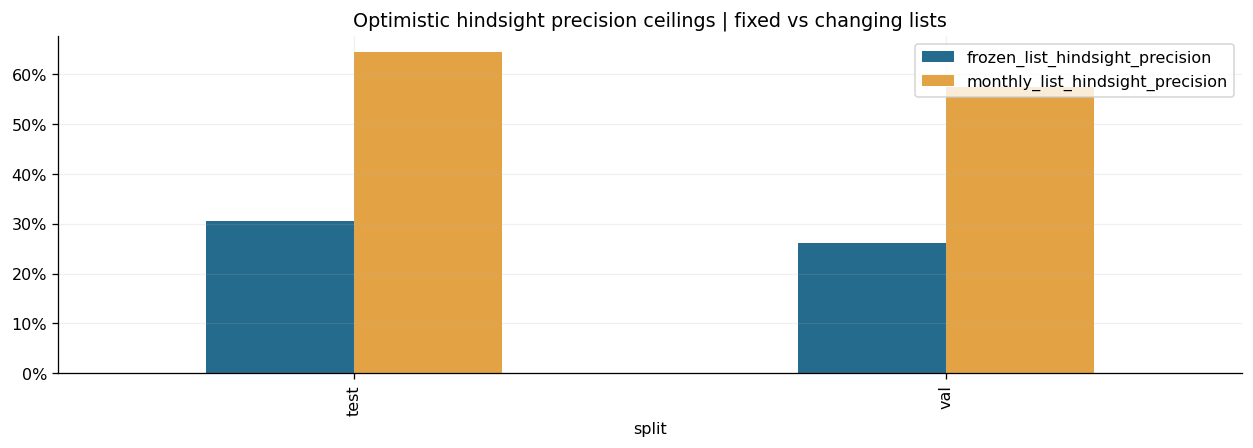

Difference isolates a capacity cost of repeating the same list across months. It is not a measured model gain.


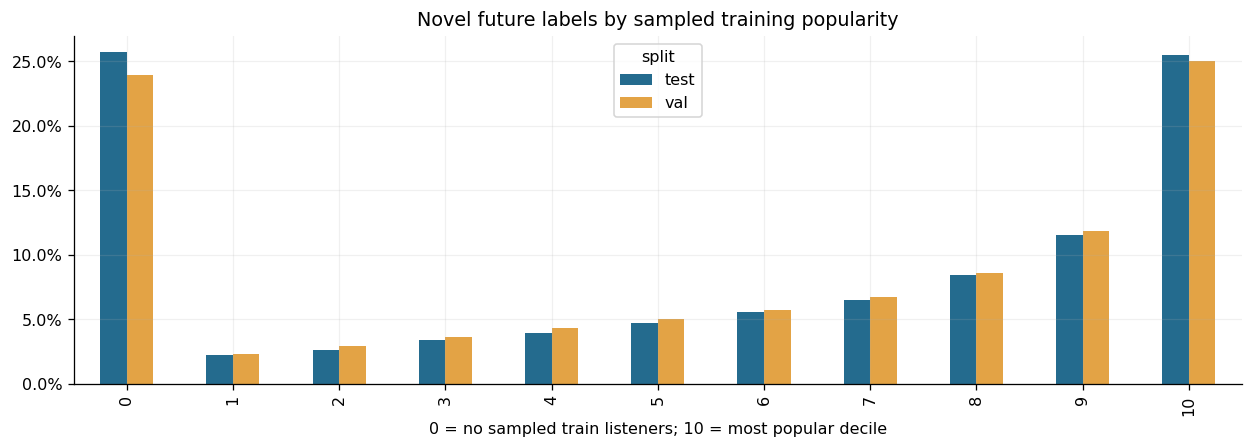

In [ ]:
# Hindsight static-list ceiling for average monthly precision, conditional on original warm-eligible queries.
# Every counted label is in an eligible query. Rank each user's candidates by number of target months.
# This maximizes total hits for a frozen list; it uses future labels and is NOT a deployable recommender.
static_freq=query("""SELECT user_id,split,item_id,count(*) target_months FROM labels
 WHERE in_cohort=1 AND item_status='warm fitted' AND seen_raw=0 GROUP BY user_id,split,item_id""")
static_freq=static_freq.sort_values(['split','user_id','target_months','item_id'],ascending=[True,True,False,True])
static_hits=static_freq.groupby(['split','user_id']).head(K).groupby('split').target_months.sum()
monthly_ceil=query("""SELECT split,user_id,ym,count(*) r FROM labels WHERE in_cohort=1 AND item_status='warm fitted' AND seen_raw=0 GROUP BY split,user_id,ym""")
month_hits=monthly_ceil.assign(h=lambda x:np.minimum(x.r,K)).groupby('split').h.sum()
counts=monthly_ceil.groupby('split').size()
ceiling=pd.DataFrame({'frozen_list_hindsight_precision':static_hits/(K*counts),
                      'monthly_list_hindsight_precision':month_hits/(K*counts),
                      'eligible_queries':counts})
assert (ceiling.frozen_list_hindsight_precision<=ceiling.monthly_list_hindsight_precision+1e-12).all()
display(ceiling)
ax=ceiling.iloc[:,:2].plot.bar();ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_title('Optimistic hindsight precision ceilings | fixed vs changing lists')
finish('static_list_hindsight_ceiling')
print('Difference isolates a capacity cost of repeating the same list across months. It is not a measured model gain.')
# Train-popularity stratification of FUTURE novel labels; bins never use future popularity.
ordered=train_items.sort_values(['listeners','item_id']).reset_index(drop=True)
ordered['popularity_decile']=np.minimum(10,(np.arange(len(ordered))*10//len(ordered)+1))
table(ordered[['item_id','popularity_decile','listeners']],'train_pop_bins')
pop_targets=query("""SELECT l.split,coalesce(p.popularity_decile,0) popularity_decile,count(*) labels
 FROM labels l LEFT JOIN train_pop_bins p USING(item_id) WHERE l.in_cohort=1 AND l.seen_raw=0
 GROUP BY l.split,coalesce(p.popularity_decile,0)""")
p=pop_targets.pivot(index='popularity_decile',columns='split',values='labels').fillna(0)
p.div(p.sum(axis=0),axis=1).plot.bar();plt.gca().yaxis.set_major_formatter(PercentFormatter(1));plt.title('Novel future labels by sampled training popularity');plt.xlabel('0 = no sampled train listeners; 10 = most popular decile')
finish('target_popularity')


## 9. Popularity drift, calendar patterns, and exposure

Raw month totals conflate the number of days, active users, changing population, and taste. Use rates and normalize within each year. Repeated month-of-year patterns across training years are descriptive evidence; one pooled monthly plot cannot separate seasonality from trend.

Jensen–Shannon distance below compares song distributions, using a common track universe and small additive smoothing. We show both the changing population and the fixed raw-training-user cohort. A fixed cohort still changes its active composition each month. This is a distributional diagnostic, not a significance test or causal attribution.


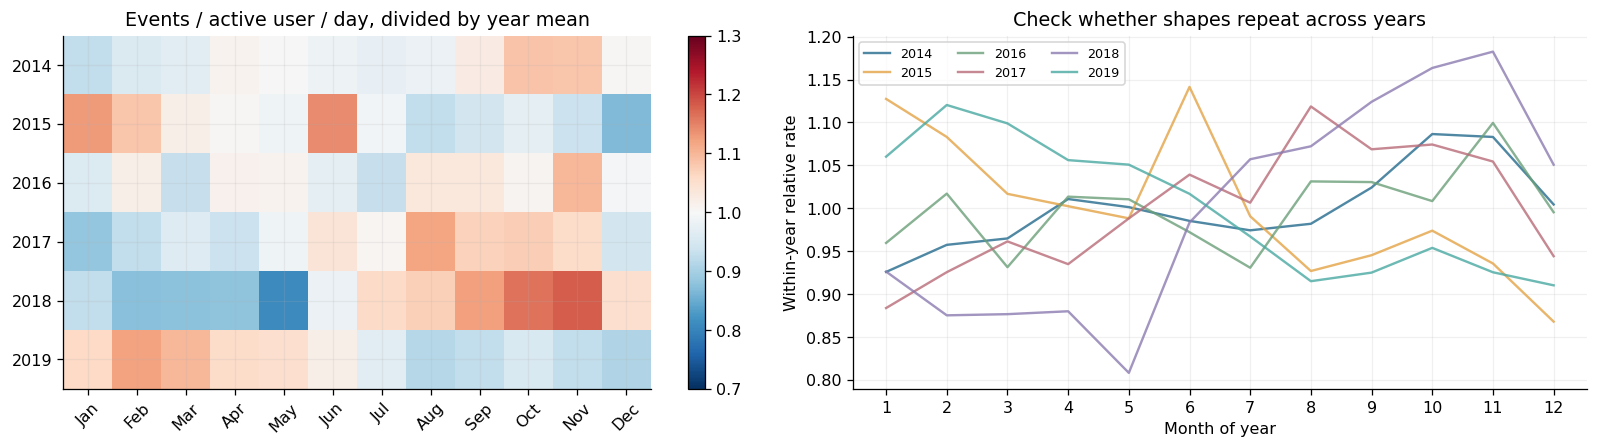

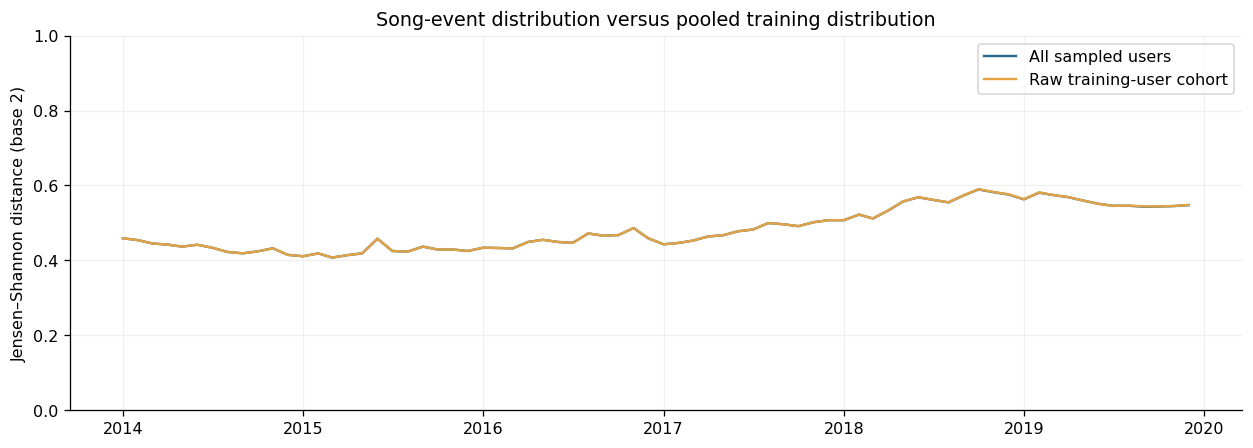

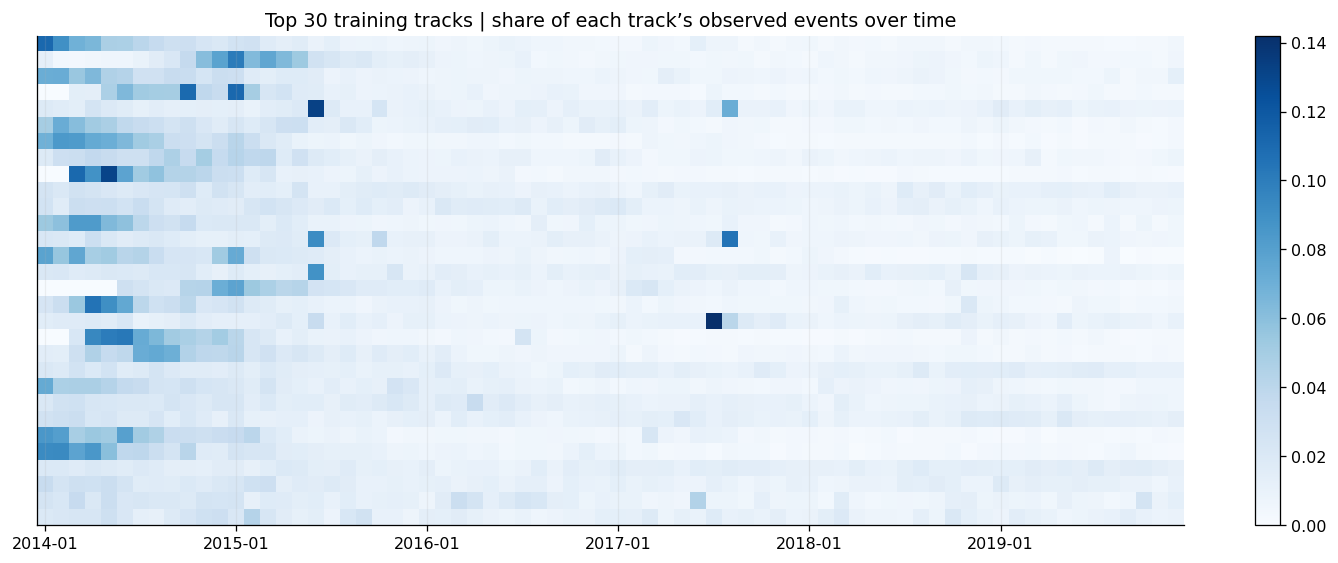

In [ ]:
calendar_data=monthly.copy();calendar_data['year']=calendar_data.date.dt.year;calendar_data['month']=calendar_data.date.dt.month
calendar_data['events_per_active_user_day']=calendar_data.events/np.maximum(calendar_data.users,1)/calendar_data.days
p=calendar_data.pivot(index='year',columns='month',values='events_per_active_user_day').reindex(columns=range(1,13))
normalized=p.div(p.mean(axis=1),axis=0)
fig,axes=plt.subplots(1,2,figsize=(14,4))
im=axes[0].imshow(normalized,aspect='auto',cmap='RdBu_r',vmin=.7,vmax=1.3)
axes[0].set_xticks(range(12),[calendar.month_abbr[m] for m in range(1,13)],rotation=45)
axes[0].set_yticks(range(len(p)),p.index);axes[0].set_title('Events / active user / day, divided by year mean');fig.colorbar(im,ax=axes[0])
for y,row in normalized.iterrows():axes[1].plot(range(1,13),row,label=str(y),alpha=.8)
axes[1].set_xticks(range(1,13));axes[1].set_xlabel('Month of year');axes[1].set_ylabel('Within-year relative rate');axes[1].legend(ncol=3,fontsize=8);axes[1].set_title('Check whether shapes repeat across years')
finish('calendar_patterns')
item_month=query('SELECT ym,item_id,count(*) events FROM events GROUP BY ym,item_id')
fixed_item_month=query('SELECT e.ym,e.item_id,count(*) events FROM events e JOIN raw_train_users u USING(user_id) GROUP BY e.ym,e.item_id')
all_ids=sorted(item_totals.item_id)
def js_profile(frame):
    mat=frame.pivot(index='ym',columns='item_id',values='events').reindex(index=expected,columns=all_ids).fillna(0)
    base=frame[frame.ym.lt(f'{VAL_YEAR}-01')].groupby('item_id').events.sum().reindex(all_ids,fill_value=0).to_numpy()+1e-8
    base=base/base.sum()
    return pd.Series({ym:jensenshannon(row.to_numpy()+1e-8,base,base=2) if row.sum()>0 else np.nan for ym,row in mat.iterrows()})
js_all=js_profile(item_month);js_fixed=js_profile(fixed_item_month)
fig,ax=plt.subplots();ax.plot(pd.to_datetime(js_all.index),js_all,label='All sampled users');ax.plot(pd.to_datetime(js_fixed.index),js_fixed,label='Raw training-user cohort')
ax.set_ylim(0,1);ax.set_ylabel('Jensen–Shannon distance (base 2)');ax.set_title('Song-event distribution versus pooled training distribution');ax.legend()
finish('popularity_drift')
# Train-year patterns for the 30 highest-listener TRAIN songs, without selecting on future peaks.
head_ids=train_items.nlargest(30,'listeners').item_id
hm=item_month[item_month.item_id.isin(head_ids)].pivot(index='item_id',columns='ym',values='events').reindex(index=head_ids,columns=expected).fillna(0)
hm=hm.div(np.maximum(hm.sum(axis=1),1),axis=0)
fig,ax=plt.subplots(figsize=(13,5));im=ax.imshow(hm,aspect='auto',cmap='Blues');ax.set_yticks([]);ax.set_xticks(np.arange(0,len(expected),12),expected[::12]);ax.set_title('Top 30 training tracks | share of each track’s observed events over time');fig.colorbar(im,ax=ax)
finish('head_track_timeline')


## 10. Content-feature completeness and geometry (optional)

`FEATURE_MODE='available'` audits only local raw feature files. Choose `'download'` to obtain the five modalities used in the content notebook (roughly 390 MiB compressed combined). The very wide tag table can be slow to parse even though its compressed download is small. No dense item × 178,108 tag matrix is allocated.

For each modality distinguish **absent row**, **malformed row**, **nonfinite values**, **valid zero vector**, and **usable nonzero vector**. A row-presence percentage alone cannot establish usable coverage. Ragged rows are rejected, not silently padded/truncated. For compact modalities, PCA is fitted on usable warm training items and only projects other groups; a 2D projection is a geometry illustration, not evidence of recommendation quality.

The feature groups and “cold” status remain relative to this sampled window. Metadata timestamps are not supplied by this audit: fitting a scaler on training tracks does not establish historical availability of tags or externally pretrained representations.


/content/music4all_onion/raw/id_genres_tf-idf.tsv.bz2
Auditing id_genres_tf-idf.tsv.bz2
Not available locally: id_tags_tf-idf.tsv.bz2
/content/music4all_onion/raw/id_ivec256.tsv.bz2


ERROR:tornado.application:Exception in callback functools.partial(<bound method OutStream._flush of <ipykernel.iostream.OutStream object at 0x7c7d81e5d810>>)
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/tornado/ioloop.py", line 758, in _run_callback
    ret = callback()
  File "/usr/local/lib/python3.13/dist-packages/ipykernel/iostream.py", line 518, in _flush
    self.session.send(
    ~~~~~~~~~~~~~~~~~^
        self.pub_thread,
        ^^^^^^^^^^^^^^^^
    ...<3 lines>...
        ident=self.topic,
        ^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 820, in send
    msg = self.msg(
        msg_or_type,
    ...<3 lines>...
        metadata=metadata,
    )
  File "/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py", line 661, in msg
    header = self.msg_header(msg_type) if header is None else header
             ~~~~~~~~~~~~~~~^^^^^^^^^^
  File "/usr/local/lib/python3

/content/music4all_onion/raw/id_lyrics_word2vec.tsv.bz2
Auditing id_lyrics_word2vec.tsv.bz2
/content/music4all_onion/raw/id_lyrics_sentiment_functionals.tsv.bz2
Auditing id_lyrics_sentiment_functionals.tsv.bz2


,modality,item_status,items,dimension,row_presence,valid_fraction,usable_nonzero_fraction,valid_zero_fraction
0,genres,filtered train item,6203,685,1.0,1.0,0.999516,0.000484
1,genres,no sampled train item,7791,685,1.0,1.0,0.999743,0.000257
2,genres,warm fitted,41834,685,1.0,1.0,0.999785,0.000215
3,audio,filtered train item,6203,100,1.0,1.0,1.000000,0.000000
4,audio,no sampled train item,7791,100,1.0,1.0,1.000000,0.000000
5,audio,warm fitted,41834,100,1.0,1.0,1.000000,0.000000
6,lyrics_embedding,filtered train item,6203,300,1.0,1.0,0.931646,0.068354
7,lyrics_embedding,no sampled train item,7791,300,1.0,1.0,0.931588,0.068412
8,lyrics_embedding,warm fitted,41834,300,1.0,1.0,0.890400,0.109600
9,lyrics_sentiment,filtered train item,6203,64,1.0,1.0,0.931646,0.068354


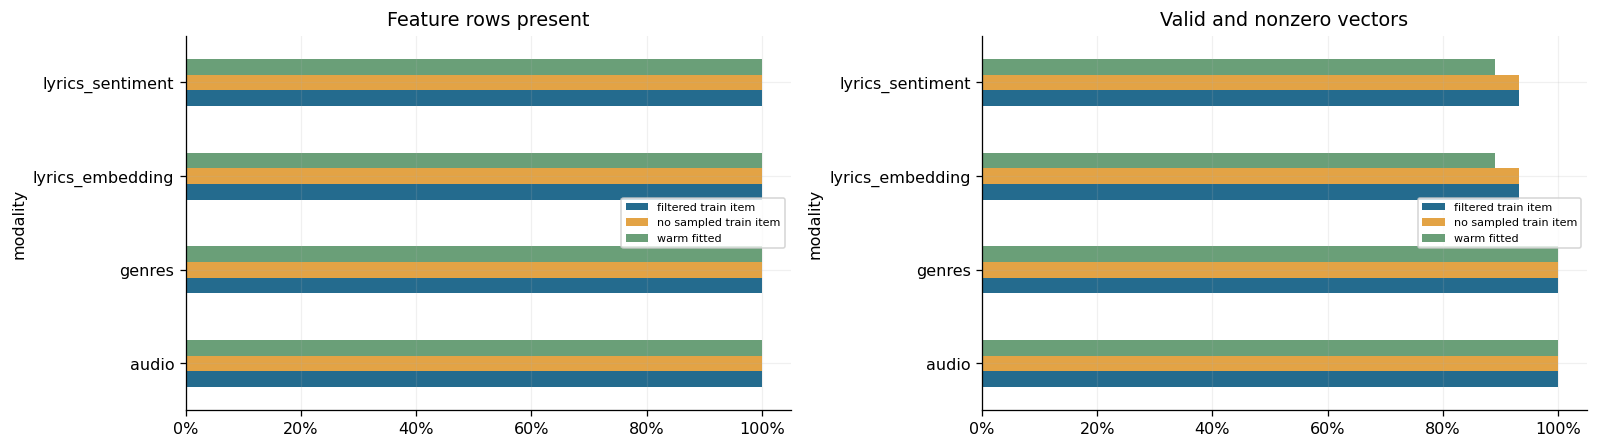

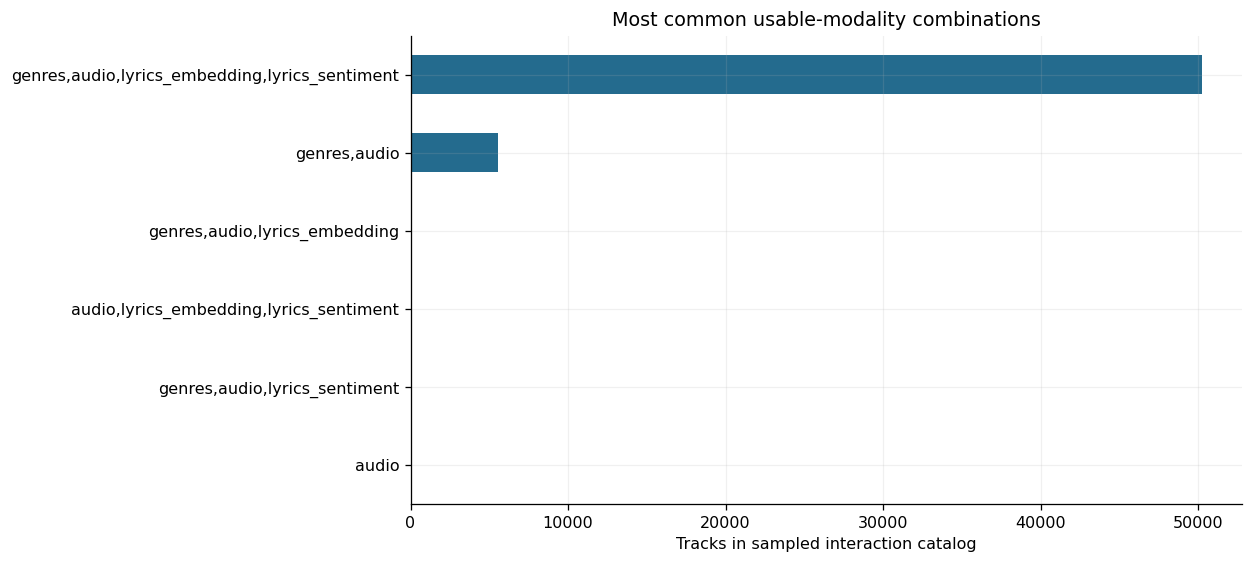

In [ ]:
FEATURES={
 'genres':('id_genres_tf-idf.tsv.bz2','a742b5fa1d2e2ce780101773e57bb7f5'),
 'tags':('id_tags_tf-idf.tsv.bz2','6681d5c2bf214ad54465286fbbab1ed4'),
 'audio':('id_ivec256.tsv.bz2','ae244a772e1e6711c34d94530e429d6f'),
 'lyrics_embedding':('id_lyrics_word2vec.tsv.bz2','d0f247bdb645e35955cd40c802ef2af2'),
 'lyrics_sentiment':('id_lyrics_sentiment_functionals.tsv.bz2','76ee907deda85b10e645731ee496a9e7')}
feature_catalog=item_totals[['item_id']].copy()
feature_catalog['item_status']=np.where(feature_catalog.item_id.isin(set(fit_items.item_id)),'warm fitted',
    np.where(feature_catalog.item_id.isin(set(train_items.item_id)),'filtered train item','no sampled train item'))
lookup={v:i for i,v in enumerate(feature_catalog.item_id)}
feature_summaries=[];feature_flags={};compact={};feature_file_info=[]
def audit_feature(path):
    n=len(feature_catalog);present=np.zeros(n,bool);valid=np.zeros(n,bool);nonzero=np.zeros(n,bool)
    counts=dict(rows=0,duplicate_ids=0,ragged_rows=0,nonfinite_rows=0,invalid_numeric_rows=0)
    seen=set()
    with bz2.open(path,'rt',encoding='utf-8',errors='strict') as f:
        header=f.readline().rstrip('\r\n').split('\t');dim=len(header)-1
        if dim<1:raise ValueError(f'Invalid feature header: {path}')
        mat=np.full((n,dim),np.nan,dtype=np.float32) if dim<=512 else None
        for line in f:
            counts['rows']+=1
            raw_id,sep,payload=line.rstrip('\r\n').partition('\t');raw_id=raw_id.strip()
            if raw_id in seen:
                counts['duplicate_ids']+=1
                raise ValueError(f'Duplicate feature ID in {path.name}: {raw_id}; resolve before alignment.')
            seen.add(raw_id)
            ix=lookup.get(raw_id)
            if ix is None:continue
            present[ix]=True
            if not sep or payload.count('\t')+1!=dim:counts['ragged_rows']+=1;continue
            # Delimiter width and parsed length both checked: bad numeric tokens cannot silently shift columns.
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter('error',DeprecationWarning)
                    arr=np.fromstring(payload,sep='\t',dtype=np.float32)
            except (ValueError,DeprecationWarning):
                counts['invalid_numeric_rows']+=1;continue
            if len(arr)!=dim:counts['invalid_numeric_rows']+=1;continue
            if not np.isfinite(arr).all():counts['nonfinite_rows']+=1;continue
            valid[ix]=True;nonzero[ix]=bool(np.any(arr!=0))
            if mat is not None:mat[ix]=arr
    flags=pd.DataFrame({'item_id':feature_catalog.item_id,'present':present,'valid':valid,'nonzero':nonzero})
    return flags,mat,dim,counts
if RUN_FEATURE_AUDIT and FEATURE_MODE!='skip':
    for name,(filename,md5) in FEATURES.items():
        path=ROOT/'raw'/filename
        if not path.exists() and FEATURE_MODE=='available':print('Not available locally:',filename);continue
        path=obtain(filename,md5)
        print('Auditing',filename)
        flags,mat,dim,counts=audit_feature(path);feature_flags[name]=flags
        if mat is not None:compact[name]=mat
        feature_file_info.append({'modality':name,'dimension':dim,'file':stat_signature(path),'md5':md5,'counts':counts})
        joined=feature_catalog.merge(flags,on='item_id')
        for status,g in joined.groupby('item_status'):
            feature_summaries.append({'modality':name,'item_status':status,'items':len(g),'dimension':dim,
                'row_presence':g.present.mean(),'valid_fraction':g.valid.mean(),'usable_nonzero_fraction':g.nonzero.mean(),
                'valid_zero_fraction':(g.valid & ~g.nonzero).mean()})
feature_summary=pd.DataFrame(feature_summaries)
if not feature_summary.empty:
    display(feature_summary)
    fig,axes=plt.subplots(1,2,figsize=(14,4))
    for ax,metric,title in zip(axes,['row_presence','usable_nonzero_fraction'],['Feature rows present','Valid and nonzero vectors']):
        feature_summary.pivot(index='modality',columns='item_status',values=metric).plot.barh(ax=ax)
        ax.set_xlim(0,1.05);ax.xaxis.set_major_formatter(PercentFormatter(1));ax.set_title(title);ax.legend(fontsize=7)
    finish('feature_completeness')
    flags_matrix=pd.DataFrame({name:frame.nonzero.to_numpy() for name,frame in feature_flags.items()})
    patterns=flags_matrix.apply(lambda row:','.join(row.index[row]) or 'none',axis=1).value_counts().head(15)
    ax=patterns.sort_values().plot.barh(figsize=(11,5));ax.set_title('Most common usable-modality combinations');ax.set_xlabel('Tracks in sampled interaction catalog')
    finish('modality_combinations')
else:print('No raw feature files audited. Recorded coverage in Section 1 remains row-presence evidence only.')


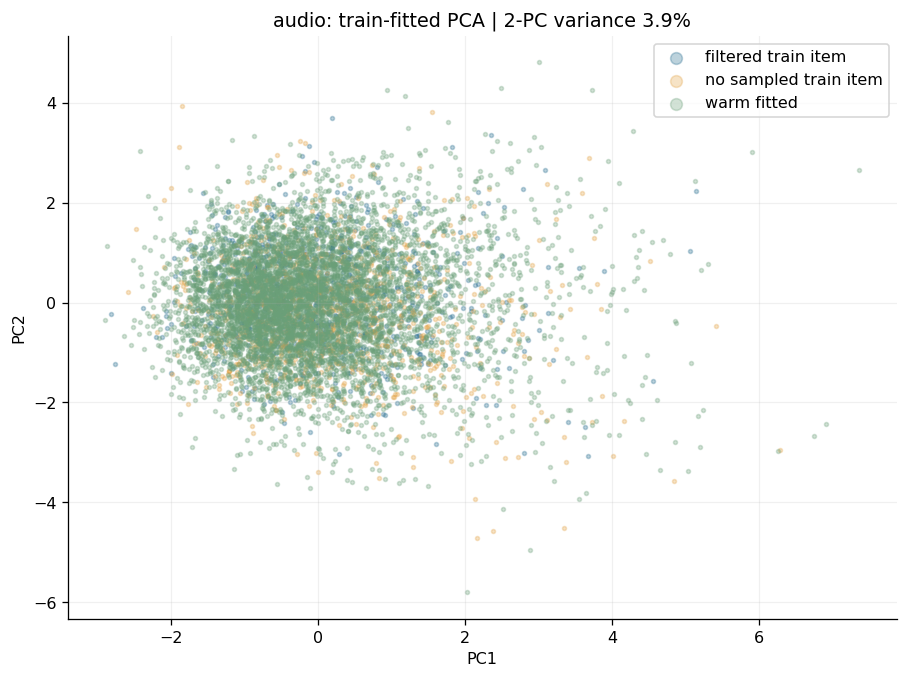

,0,1,2
Absent block encoded as zeros,0.000000,0.000000,0.000000
After centering and unit normalization,-0.622171,-0.475191,-0.622171
After preserving missingness mask,0.000000,0.000000,0.000000


Missing rows can become identical nonzero vectors after centering. Apply missingness masks after every transform.


In [ ]:
# Connect missingness to sampled training popularity; this is selection association, not causation.
if 'tags' in feature_flags:
    tag=feature_flags['tags'].merge(ordered[['item_id','popularity_decile']],on='item_id',how='left')
    tag['popularity_decile']=tag.popularity_decile.fillna(0).astype(int)
    rates=tag.groupby('popularity_decile').agg(usable=('nonzero','mean'),items=('item_id','size'))
    ax=rates.usable.plot.bar();ax.set_ylim(0,1);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_title('Usable tag coverage by training popularity');ax.set_xlabel('0 = no sampled train listeners; 10 = most popular decile')
    finish('tag_coverage_popularity');display(rates)
if compact:
    from sklearn.decomposition import PCA
    name='audio' if 'audio' in compact else next(iter(compact))
    mat=compact[name];ok=feature_flags[name].nonzero.to_numpy();warm=feature_catalog.item_status.eq('warm fitted').to_numpy()
    if (ok & warm).sum()>=3 and mat.shape[1]>=2:
        # Train-only centering/PCA. Preserve missingness; do not impute then treat missing vectors as real.
        pca=PCA(n_components=2,random_state=SEED).fit(mat[ok & warm])
        positions=pca.transform(mat[ok]);groups=feature_catalog.loc[ok,'item_status'].to_numpy()
        rng=np.random.default_rng(SEED);selected=np.sort(rng.choice(len(positions),min(8000,len(positions)),replace=False))
        fig,ax=plt.subplots(figsize=(8,6))
        for status in np.unique(groups):
            mask=groups[selected]==status;z=positions[selected][mask];ax.scatter(z[:,0],z[:,1],s=6,alpha=.3,label=status)
        ax.legend(markerscale=3);ax.set_xlabel('PC1');ax.set_ylabel('PC2')
        ax.set_title(f'{name}: train-fitted PCA | 2-PC variance {pca.explained_variance_ratio_.sum():.1%}')
        finish('feature_pca')
# Algebraic illustration, not a measurement of real songs.
from sklearn.preprocessing import StandardScaler, normalize
example=np.array([[1.,2.,1.],[2.,1.,3.],[3.,4.,2.]])
scaler=StandardScaler().fit(example)
missing=np.zeros((1,3))
wrong=normalize(scaler.transform(missing))[0]
correct=np.zeros_like(wrong) # Restore missing block after transformation, then combine available modalities.
display(pd.DataFrame([missing[0],wrong,correct],index=['Absent block encoded as zeros','After centering and unit normalization','After preserving missingness mask']))
print('Missing rows can become identical nonzero vectors after centering. Apply missingness masks after every transform.')


## 11. Sensitivity to user sampling and single-pass thresholds

These tables are **descriptive sensitivity analyses**, not hyperparameter selection from test data. A fixed minimum of five sampled listeners becomes more restrictive as fewer users are sampled. In general, five listeners in a 10% user sample is not equivalent to five in the full population, and item-cold status can change with the sample.

The nested-sample analysis takes deterministic subsets of the already selected users. Its fractions are relative to this parent sample, not a new random sample of the full population. It is a controlled illustration of sampling effects; it does not recover unsampled users or establish full-population zero interactions.


,minimum_user_songs,minimum_item_listeners,pairs,users,items,events,pair_retention,density
0,1,1,2132298,5933,48037,9769411,1.000000,0.007482
1,2,2,2130515,5744,46443,9759891,0.999164,0.007986
2,5,5,2116066,5463,41834,9692593,0.992388,0.009259
3,10,10,2073322,5189,35893,9504338,0.972342,0.011132
4,20,20,1950930,4818,27632,8992564,0.914942,0.014654


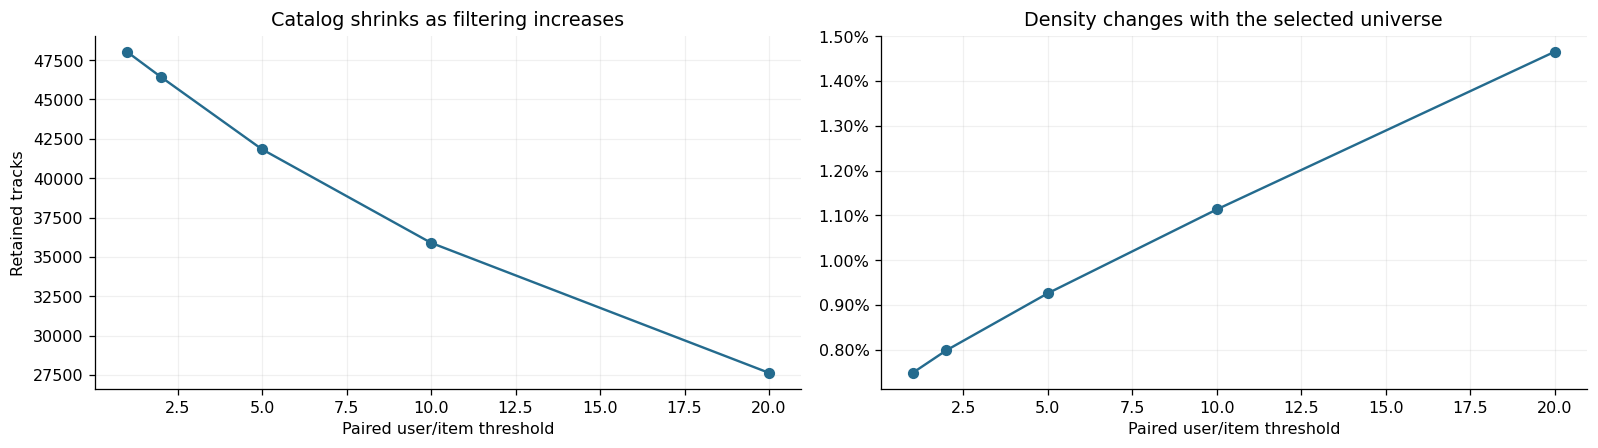

,fraction_of_parent_users,users,items_with_min_listeners,observed_items,pairs
0,0.25,1512,28855,44093,553976
1,0.50,2981,36450,46540,1081223
2,1.00,5933,41841,48037,2132298


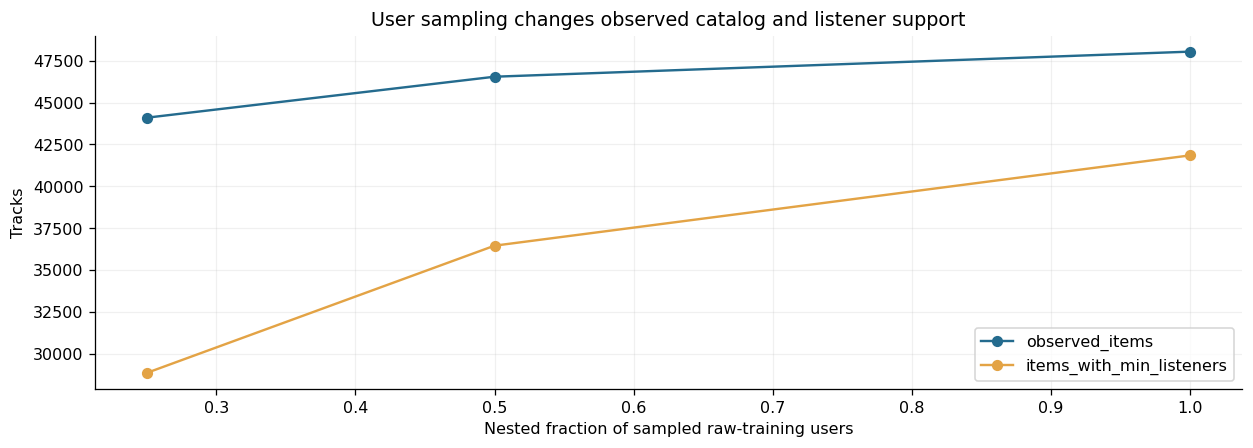

In [ ]:
threshold_rows=[]
for iu,ii in [(1,1),(2,2),(5,5),(10,10),(20,20)]:
    frame=query("""WITH ru AS (SELECT user_id FROM raw_train_pairs GROUP BY user_id HAVING count(*)>=?),
    ri AS (SELECT p.item_id FROM raw_train_pairs p JOIN ru USING(user_id) GROUP BY p.item_id HAVING count(*)>=?),
    fp AS (SELECT p.* FROM raw_train_pairs p JOIN ru USING(user_id) JOIN ri USING(item_id))
    SELECT count(*) pairs,count(DISTINCT user_id) users,count(DISTINCT item_id) items,sum(plays) events FROM fp""",(iu,ii)).iloc[0].to_dict()
    threshold_rows.append({'minimum_user_songs':iu,'minimum_item_listeners':ii,**frame})
thresholds=pd.DataFrame(threshold_rows);thresholds['pair_retention']=thresholds.pairs/Nraw
thresholds['density']=thresholds.pairs/(thresholds.users*thresholds['items']).replace(0,np.nan)
display(thresholds)
fig,axes=plt.subplots(1,2,figsize=(14,4))
axes[0].plot(thresholds.minimum_item_listeners,thresholds['items'],marker='o');axes[0].set_ylabel('Retained tracks');axes[0].set_xlabel('Paired user/item threshold');axes[0].set_title('Catalog shrinks as filtering increases')
axes[1].plot(thresholds.minimum_item_listeners,thresholds.density,marker='o');axes[1].yaxis.set_major_formatter(PercentFormatter(1));axes[1].set_xlabel('Paired user/item threshold');axes[1].set_title('Density changes with the selected universe')
finish('threshold_sensitivity')
# Stable secondary hash gives nested subsets, independent of the original sampling hash.
subset_hash={u:int.from_bytes(hashlib.sha256(f'nested:{SEED}:{u}'.encode()).digest()[:8],'big')/2**64 for u in train_users.user_id}
sample_rows=[]
for fraction in [.25,.5,1.]:
    ids=[u for u in train_users.user_id if subset_hash[u]<fraction]
    table(pd.DataFrame({'user_id':pd.Series(ids,dtype=str)}),'nested_users')
    row=query('SELECT count(DISTINCT p.item_id) observed_items,count(*) pairs FROM raw_train_pairs p JOIN nested_users u USING(user_id)').iloc[0].to_dict()
    qualified=int(scalar('SELECT count(*) FROM (SELECT p.item_id FROM raw_train_pairs p JOIN nested_users u USING(user_id) GROUP BY p.item_id HAVING count(*)>=?)',(MIN_ITEM,)))
    sample_rows.append({'fraction_of_parent_users':fraction,'users':len(ids),'items_with_min_listeners':qualified,**row})
sample_sensitivity=pd.DataFrame(sample_rows);display(sample_sensitivity)
ax=sample_sensitivity.set_index('fraction_of_parent_users')[['observed_items','items_with_min_listeners']].plot(marker='o');ax.set_xlabel('Nested fraction of sampled raw-training users');ax.set_ylabel('Tracks');ax.set_title('User sampling changes observed catalog and listener support')
finish('nested_user_sampling')


## 12. Turn measurements into defensible conclusions

| Observation or limitation | Type | Consequence | Useful response |
|---|---|---|---|
| Unobserved listens are not dislikes | Implicit-feedback limitation | Offline zeros mix nonexposure and lack of interest | Describe observed-listen retrieval; use exposure/user studies for enjoyment claims |
| Content universe exceeds interaction universe | Dataset coverage | Much of the content catalog has no interaction supervision | Report both universes and define an independent candidate catalog |
| Some raw-training items disappear under filtering | Protocol choice | Outside-fitted-catalog songs mix historical and unseen items | Preserve separate item groups and raw-history masks |
| Sampling changes listener counts and cold status | Sample effect | Thresholds and “zero history” depend on the sampled population | State scope; compare nested samples; use full source for global claims |
| User observation declines over time | Measured cohort/coverage property | Conditional metrics represent a smaller selected group | Report fixed-cohort participation beside ranking metrics |
| Four years of history are frozen through 2019 | Protocol choice | Longer horizon and stale preferences confound architecture assessment | Compare frozen monthly, frozen annual, and past-only rolling benchmarks |
| Previously heard songs dominate many future labels | Task choice applied to behavior | Discovery excludes a large part of natural listening | Evaluate repeat consumption and discovery separately |
| Candidate catalog comes from future observed items | Retrospective construction | Candidate presence uses future information | Declare retrospective catalog; use availability metadata when possible |
| Feature collection times are unknown | Metadata provenance gap | Historical content availability cannot be established | Audit provenance; avoid asserting complete temporal leakage freedom |
| Missing modalities can become nonzero after centering | Preprocessing issue | Artificial similarity can dominate missing-feature songs | Preserve masks; measure valid nonzero coverage and stratify results |
| Small differences between model scores | Evidence limitation | Point estimates cannot establish a reliable winner | Bootstrap users and repeat training seeds |

Do not infer a causal explanation for low NDCG from a single correlation or plot. Measure changes to one protocol component at a time and keep query sets/candidate sets aligned when making direct comparisons. Cold-only and mixed-catalog scores have different target and candidate definitions.


In [ ]:
# A compact computed diagnostic card. Statements remain scoped to the loaded sample.
test_funnel=funnel[funnel.year.eq(TEST_YEAR)].iloc[0]
test_labels=coverage[coverage.split.eq('test')].groupby('category').labels.sum()
findings=pd.DataFrame([
    ['Observed event scope',f'{cleaning["deduplicated_events"]:,} deduplicated sampled/window events',mode],
    ['Raw training density',f'{raw_density:.3%}','Sampled raw training vocabulary'],
    ['Fitted training density',f'{nfit/(len(fit_users)*len(fit_items)):.3%}','Single-pass filtered vocabulary'],
    ['Test cohort participation',f'{test_funnel.warm_eligible_users/len(cohort):.1%} of selected users have a warm query','Conditional ranking scope'],
    ['Warm discovery label share',f'{test_labels.get("6 warm discovery",0)/test_labels.sum():.1%}','All distinct future user–month–song labels'],
    ['Training event concentration',f'Top 10% of tracks receive {head[2]:.1%} of train events','Sampled raw training'],
    ['History horizon','Test query starts are at least one year after the training cutoff','Frozen setup'],
],columns=['diagnostic','result','scope'])
display(findings)
print('First observation in this sample is not release. No sampled training events is not globally no history.')
print('No plot here establishes user enjoyment, causal model failure, or that a weak ranking score is adequate.')


,diagnostic,result,scope
0,Observed event scope,"13,362,376 deduplicated sampled/window events",raw
1,Raw training density,0.748%,Sampled raw training vocabulary
2,Fitted training density,0.926%,Single-pass filtered vocabulary
3,Test cohort participation,29.0% of selected users have a warm query,Conditional ranking scope
4,Warm discovery label share,36.2%,All distinct future user–month–song labels
5,Training event concentration,Top 10% of tracks receive 49.7% of train events,Sampled raw training
6,History horizon,Test query starts are at least one year after ...,Frozen setup


First observation in this sample is not release. No sampled training events is not globally no history.
No plot here establishes user enjoyment, causal model failure, or that a weak ranking score is adequate.


## 13. Export and reproducibility

The analysis writes aggregate CSVs and figure PNGs into `OUT`, plus a configuration/source manifest. Original event and model files are unchanged. The SQLite database holds sampled identifiers and events for local analysis; it is not necessary to share that database to share the aggregate report.

Checksums verify downloaded bytes; the analysis cache additionally keys on requested years, sample, file size, and modification time. To analyze a changed source, choose a new `OUT`. The CSVs are generated measurements from this run; Section 1’s recorded evidence is exported separately so it cannot be mistaken for a fresh computation.


In [ ]:
exports={
 'recorded_catalog_scopes':recorded_scope,'recorded_splits':recorded_splits,'recorded_test_label_coverage':recorded_coverage,
 'cleaning':pd.Series(cleaning,name='rows').rename_axis('stage').reset_index(),
 'split_summary':summary,'monthly_activity':monthly.drop(columns=['date']),
 'density_comparison':density_table.reset_index(names='scope'),'future_label_status_cross_tab':coverage_cross,
 'future_label_decomposition':coverage,'outside_fitted_seen_history':seen_outside,'evaluation_funnel':funnel,
 'history_size_summary':history.reset_index(),'temporal_target_counts':temporal.groupby(['split','ym'])[['frozen_targets','rolling_targets']].sum().reset_index(),
 'random_query_average':reference.reset_index(),'random_user_macro':user_macro.reset_index(),
 'hindsight_precision_ceilings':ceiling.reset_index(),'target_popularity':pop_targets,
 'threshold_sensitivity':thresholds,'nested_user_sample_sensitivity':sample_sensitivity,'computed_findings':findings,
 'cohort_year_activity':cohort_frac.reset_index(),'js_drift':pd.DataFrame({'ym':expected,'all_sample_users':js_all.values,'raw_training_users':js_fixed.values})}
if not feature_summary.empty:exports['feature_coverage']=feature_summary
for name,df in exports.items():df.to_csv(OUT/(name+'.csv'),index=False)
manifest={'contract':CONTRACT,'cleaning':cleaning,'analysis_config':{'minimum_user_songs':MIN_USER,'minimum_item_listeners':MIN_ITEM,'K':K,'eval_limit':EVAL_LIMIT,
    'actual_cohort_users':len(cohort),'cohort_origin':cohort_origin,'feature_mode':FEATURE_MODE},
 'feature_files':feature_file_info,'versions':{'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,'sqlite':sqlite3.sqlite_version},
 'figures':FIGURES,'csv_files':[name+'.csv' for name in exports],
 'sources':['https://zenodo.org/records/15394646','https://zenodo.org/records/15394646/files/README.md?download=1',
            'music4all_onion_latent_factor_colab.ipynb','music4all_onion_content_based_colab.ipynb'],
 'interpretation':'Exploratory audit. Cold/first-observed status is scoped to the loaded user sample and time window.'}
(OUT/'ANALYSIS_MANIFEST.json').write_text(json.dumps(manifest,indent=2,default=str))
con.commit()
print(f'Exported {len(exports)} aggregate tables and {len(FIGURES)} figure files to {OUT}')
print('Completed analysis. Inspect computed findings and coverage tables before comparing model scores.')


Exported 23 aggregate tables and 23 figure files to /content/music4all_onion/dataset_analysis/users10pct_2014_2019_v1
Completed analysis. Inspect computed findings and coverage tables before comparing model scores.


In [ ]:
# 1. Zip the folder (replace 'my_folder' with your folder's name)
# !zip -r /content/dataset_analysis.zip /content/music4all_onion/dataset_analysis

from google.colab import files
files.download("/content/dataset_analysis.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Sources and provenance

- Moscati et al. (2022), *Music4All-Onion — A Large-Scale Multi-faceted Content-Centric Music Recommendation Dataset*, [paper DOI](https://doi.org/10.1145/3511808.3557656).
- [Official dataset v2](https://zenodo.org/records/15394646), published May 13, 2025; [README](https://zenodo.org/records/15394646/files/README.md?download=1), checked October 22, 2026. The README's `ivec256` describes the GMM component setting; the numeric vector dimension is measured from the file header rather than inferred from its name.
- Supplied CF notebook: saved split/cleaning counts, fitted matrix shape, test label coverage and cohort counts, and warm test metrics.
- Supplied content notebook: saved expanded catalog size, modality row-presence rates, and warm two-tower metrics. Warm two-tower values are transcribed from its saved results; model re-evaluation is outside this dataset audit.

**Validation status:** Section 1’s outputs are executed from explicitly transcribed recorded counts, not recomputed raw events. All later code cells are syntactically checked and exercised on a synthetic fixture in a separate validation run, including exact deduplication, sampled-history item groups, query coverage, random expectations, and feature row checks. The full 252-million-row release was not processed while creating this notebook.
